# Desafío Técnico - Data Scientist Lead · Optimización Logística

Notebook ejecutable que procesa los cuatro datasets y genera **todos** los resultados del desafío.
La lógica vive en el paquete `src/logistica/` (código tipado y documentado); aquí se orquesta, se visualiza y se interpreta.

| Sección | Contenido |
|---|---|
| 0 | Setup y calidad de datos |
| 1 | **Tarea 1** - Diagnóstico WAPE / Bias por CD y horizonte |
| 2 | **Tarea 2** - Estado del plan de entrega y estrategia de aplanamiento |
| 3 | **Tarea 3** - Modelo complementario + backtest con origen rodante |
| 4 | **Tarea 4** - Gate de historia mínima (Cold Start) y análisis del umbral |
| 5 | **Tarea 5** - Arquitectura AWS |
| 6 | Impacto en negocio y KPIs |
| 7 | Limitaciones y próximos pasos |

Todas las tablas y figuras se guardan en `outputs/`.

In [1]:
import sys, warnings, logging
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)
logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display, Markdown

from logistica.config import CENTROS, HORIZONTES, DIAS_SEMANA, MIN_HISTORY_DAYS, OUTPUT_DIR
from logistica.data import load_data, quality_report, daily_actuals, forecast_vs_actual
from logistica.metrics import wape, bias, error_table
from logistica.features import build_features, FEATURE_COLS, LOG_FEATURE_COLS
from logistica.models import BaselineModel, RollingBiasCorrector, MLCorrector
from logistica.backtest import make_origins, rolling_origin_backtest, summarize_backtest, history_sensitivity
from logistica.gate import HistoryGate, ResilientForecaster, continuous_history_days
from logistica import plan as P
from logistica.impact import fleet_impact
from logistica.viz import set_style, save, COLORS, SERIES, RAMP

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 160)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pct = mtick.PercentFormatter(1.0, decimals=0)
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: C:\Users\ccarc\Desktop\DESAFIO


## 0. Carga y calidad de datos

In [2]:
pkg = load_data()
display(quality_report(pkg))

actuals = daily_actuals(pkg.pedidos)          # demanda real diaria por CD (suma de canales)
fva = forecast_vs_actual(pkg.pronostico, actuals)
print("Pronósticos sin real asociado:", fva["real"].isna().sum())
print("Días con dato por CD:", actuals.groupby("centro_distribucion")["fecha"].nunique().to_dict())
print("Filas de pronóstico por CD × horizonte:")
display(fva.pivot_table(index="centro_distribucion", columns="horizonte", values="real", aggfunc="size"))

,dataset,filas,columnas,nulos,duplicados,fecha_min,fecha_max
0,pedidos,1080,4,0,0,2026-01-01,2026-03-01
1,pronostico,1380,6,0,0,2026-01-02,2026-03-01
2,capacidad,360,3,0,0,2026-01-01,2026-03-01
3,plan,739,8,0,0,2026-01-01,2026-03-01


Pronósticos sin real asociado: 0
Días con dato por CD: {'CD_CENTRO': 60, 'CD_ESTE': 60, 'CD_NORTE': 60, 'CD_OESTE': 60, 'CD_PACIFICO': 60, 'CD_SUR': 60}
Filas de pronóstico por CD × horizonte:


horizonte,D+1,D+2,D+3,D+4
centro_distribucion,,,,
CD_CENTRO,59,58,57,56
CD_ESTE,59,58,57,56
CD_NORTE,59,58,57,56
CD_OESTE,59,58,57,56
CD_PACIFICO,59,58,57,56
CD_SUR,59,58,57,56


**Observaciones de calidad**
- Sin nulos ni duplicados; 6 CD × 60 días completos y continuos (2026-01-01 a 2026-03-01).
- El pronóstico es a nivel **CD-día**, mientras que los pedidos vienen por canal, agregamos la demanda real sumando canales (3 registros por CD-día).
- `horizonte` es consistente con `fecha_despacho − fecha_emision` (validado). Cada CD tiene 59/58/57/56 pronósticos D+1…D+4.

In [3]:
lag = (pkg.pronostico["fecha_despacho"] - pkg.pronostico["fecha_emision"]).dt.days
assert (lag == pkg.pronostico["h"]).all(), "horizonte inconsistente con fechas"
assert not pkg.pedidos.duplicated(["centro_distribucion", "fecha_despacho", "canal_venta"]).any()
assert ((pkg.plan["fecha_compra_real"] != pkg.plan["fecha_plan"]).astype(int) == pkg.plan["fuera_de_plan"]).all()
print("Validaciones de consistencia OK")

Validaciones de consistencia OK


## 1. Tarea 1 - Diagnóstico de calidad y backtesting del pronóstico base

- **WAPE** = Σ|real − pronóstico| / Σ|real|
- **Bias** = Σ(real − pronóstico) / Σ|real| -> **positivo = subestimación**, negativo = sobreestimación

In [4]:
t_total = error_table(fva, None)
t_cd = error_table(fva, "centro_distribucion").sort_values("Bias")
t_h = error_table(fva, "horizonte")
t_cd_h = error_table(fva, ["centro_distribucion", "horizonte"])
wape_cd_h = t_cd_h["WAPE"].unstack()
bias_cd_h = t_cd_h["Bias"].unstack()

display(t_total)
display(t_cd)
display(t_h)
print("WAPE por CD × horizonte"); display(wape_cd_h.style.format("{:.1%}").background_gradient(cmap=COLORS["cmap_seq"], axis=None))
print("Bias por CD × horizonte"); display(bias_cd_h.style.format("{:+.1%}").background_gradient(cmap=COLORS["cmap_div"], vmin=-0.35, vmax=0.35, axis=None))

for name, t in {"t1_total": t_total, "t1_por_cd": t_cd, "t1_por_horizonte": t_h, "t1_cd_horizonte": t_cd_h}.items():
    t.to_csv(OUTPUT_DIR / f"{name}.csv")

,WAPE,Bias,n,unidades_reales
Total,0.208,0.065,"1,380.000","2,011,978.870"


,WAPE,Bias,n,unidades_reales
centro_distribucion,,,,
CD_OESTE,0.239,-0.227,230.000,"113,037.260"
CD_PACIFICO,0.222,-0.216,230.000,"152,559.580"
CD_CENTRO,0.233,-0.202,230.000,"346,514.160"
CD_NORTE,0.098,0.075,230.000,"705,832.760"
CD_ESTE,0.259,0.253,230.000,"183,209.090"
CD_SUR,0.316,0.316,230.000,"510,826.020"


,WAPE,Bias,n,unidades_reales
horizonte,,,,
D+1,0.198,0.069,354.000,"516,024.430"
D+2,0.203,0.076,348.000,"506,799.250"
D+3,0.208,0.064,342.000,"498,206.100"
D+4,0.225,0.052,336.000,"490,949.090"


WAPE por CD × horizonte


horizonte,D+1,D+2,D+3,D+4
centro_distribucion,,,,
CD_CENTRO,19.6%,19.5%,26.7%,27.7%
CD_ESTE,24.8%,24.7%,25.4%,28.7%
CD_NORTE,8.8%,10.1%,8.5%,11.9%
CD_OESTE,25.6%,24.1%,21.9%,24.0%
CD_PACIFICO,20.3%,21.1%,21.6%,25.8%
CD_SUR,31.7%,32.3%,31.9%,30.3%


Bias por CD × horizonte


horizonte,D+1,D+2,D+3,D+4
centro_distribucion,,,,
CD_CENTRO,-19.6%,-17.6%,-20.3%,-23.5%
CD_ESTE,+24.8%,+24.7%,+24.9%,+26.9%
CD_NORTE,+8.5%,+8.7%,+6.4%,+6.2%
CD_OESTE,-25.6%,-24.1%,-20.3%,-20.5%
CD_PACIFICO,-20.3%,-20.7%,-20.8%,-24.6%
CD_SUR,+31.7%,+32.3%,+31.9%,+30.3%


### 1.1 ¿Es consistente el sesgo? % de días con subestimación y estabilidad semanal

In [5]:
fva["error"] = fva["real"] - fva["pronostico"]
consist = fva.groupby("centro_distribucion").agg(
    pct_dias_subestima=("error", lambda e: (e > 0).mean()),
    ratio_medio_real_pron=("real", "sum"),
)
consist["ratio_medio_real_pron"] = fva.groupby("centro_distribucion")["real"].sum() / fva.groupby("centro_distribucion")["pronostico"].sum()
fva["semana"] = fva["fecha_despacho"].dt.to_period("W-SUN").dt.start_time
bias_sem = fva.groupby(["semana", "centro_distribucion"]).apply(lambda g: bias(g["real"], g["pronostico"])).unstack()
consist["bias_semanal_min"] = bias_sem.min()
consist["bias_semanal_max"] = bias_sem.max()
consist["semanas_mismo_signo"] = np.sign(bias_sem).eq(np.sign(t_cd["Bias"]), axis=1).mean()
consist["diagnostico"] = np.where(consist["pct_dias_subestima"] > 0.8, "Subestima consistentemente",
                          np.where(consist["pct_dias_subestima"] < 0.2, "Sobreestima consistentemente", "Mixto"))
consist = consist.loc[t_cd.index]
display(consist.style.format({"pct_dias_subestima": "{:.0%}", "ratio_medio_real_pron": "{:.2f}",
                              "bias_semanal_min": "{:+.1%}", "bias_semanal_max": "{:+.1%}", "semanas_mismo_signo": "{:.0%}"}))
consist.to_csv(OUTPUT_DIR / "t1_consistencia_sesgo.csv")

# Error por día de la semana (¿el base captura el pico del martes?)
fva["dow"] = fva["fecha_despacho"].dt.dayofweek
t_dow = error_table(fva, "dow"); t_dow.index = DIAS_SEMANA
display(t_dow[["WAPE", "Bias"]].T.style.format("{:.1%}"))

,pct_dias_subestima,ratio_medio_real_pron,bias_semanal_min,bias_semanal_max,semanas_mismo_signo,diagnostico
centro_distribucion,,,,,,
CD_OESTE,7%,0.82,-28.4%,-17.7%,100%,Sobreestima consistentemente
CD_PACIFICO,5%,0.82,-24.1%,-18.7%,100%,Sobreestima consistentemente
CD_CENTRO,11%,0.83,-29.8%,-17.4%,100%,Sobreestima consistentemente
CD_NORTE,80%,1.08,+4.7%,+9.6%,100%,Subestima consistentemente
CD_ESTE,95%,1.34,+20.2%,+31.5%,100%,Subestima consistentemente
CD_SUR,100%,1.46,+29.8%,+35.4%,100%,Subestima consistentemente


,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado,Domingo
WAPE,19.6%,21.0%,20.0%,22.1%,21.0%,20.5%,21.7%
Bias,6.6%,8.1%,6.4%,4.3%,6.6%,8.3%,4.8%


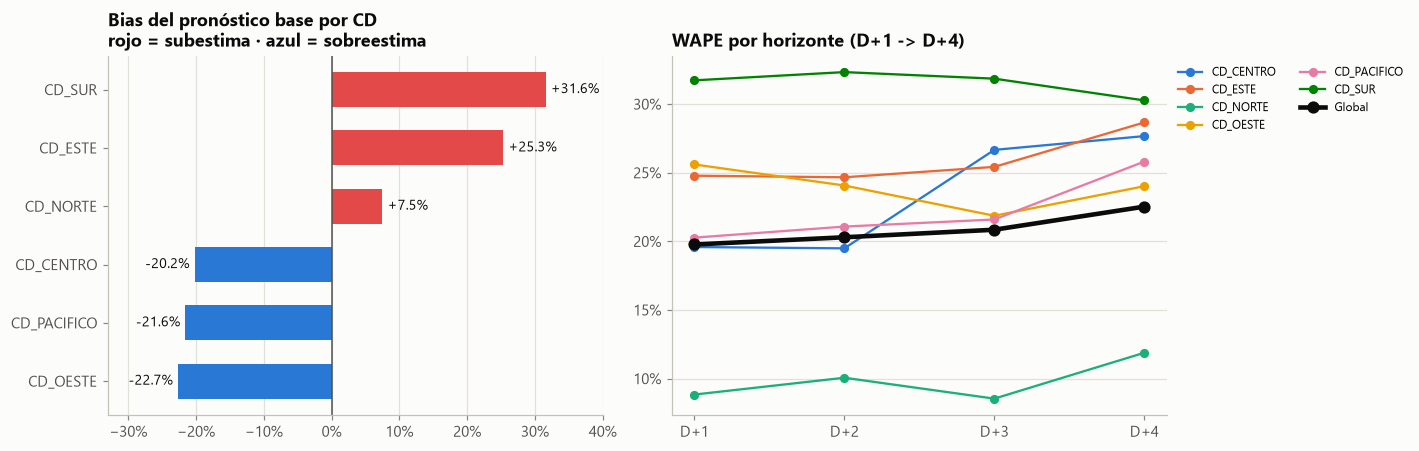

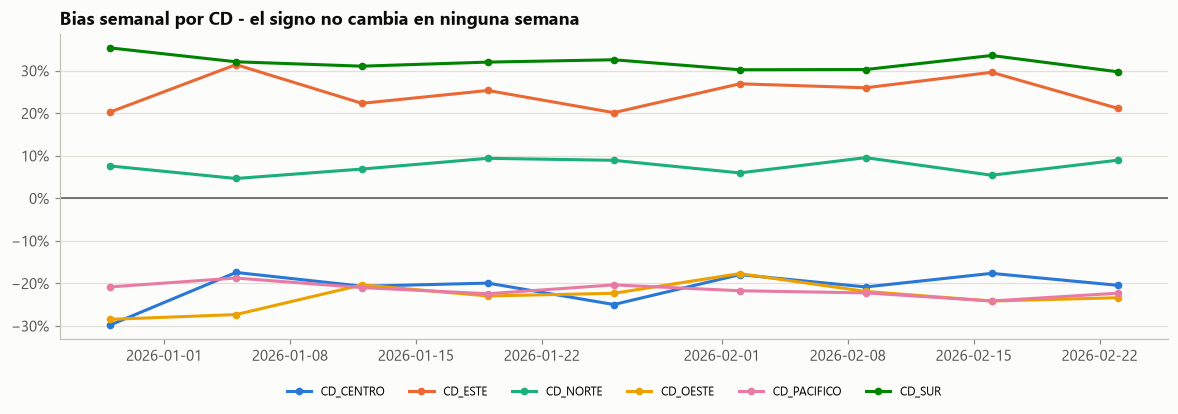

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
b = t_cd["Bias"]
ax.barh(b.index, b.values, color=[COLORS["sub"] if v > 0 else COLORS["sobre"] for v in b.values], height=0.6)
for y, v in enumerate(b.values):
    ax.text(v + (0.008 if v > 0 else -0.008), y, f"{v:+.1%}", va="center", ha="left" if v > 0 else "right", color=COLORS["ink"], fontsize=9)
ax.axvline(0, color=COLORS["ink2"], lw=1)
ax.xaxis.set_major_formatter(pct); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlim(-0.33, 0.40)
ax.set_title(f"Bias del pronóstico base por CD\n{COLORS['sub_name']} = subestima · {COLORS['sobre_name']} = sobreestima")

ax = axes[1]
for i, cd in enumerate(wape_cd_h.index):
    ax.plot(HORIZONTES, wape_cd_h.loc[cd], marker="o", ms=5, color=SERIES[i], lw=1.5, label=cd)
ax.plot(HORIZONTES, t_h["WAPE"], marker="o", ms=7, color=COLORS["ink"], lw=3, label="Global")
ax.yaxis.set_major_formatter(pct)
ax.set_title("WAPE por horizonte (D+1 -> D+4)")
ax.legend(ncol=2, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout(); save(fig, "t1_bias_wape"); plt.show()

fig, ax = plt.subplots(figsize=(13, 3.6))
for i, cd in enumerate(bias_sem.columns):
    ax.plot(bias_sem.index, bias_sem[cd], marker="o", ms=4, color=SERIES[i], label=cd)
ax.axhline(0, color=COLORS["ink2"], lw=1); ax.yaxis.set_major_formatter(pct)
ax.set_title("Bias semanal por CD - el signo no cambia en ninguna semana")
ax.legend(ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
save(fig, "t1_bias_semanal"); plt.show()

In [7]:
sub = consist.index[consist["diagnostico"].str.startswith("Sub")].tolist()
sobre = consist.index[consist["diagnostico"].str.startswith("Sobre")].tolist()
w = t_h["WAPE"]
deg_abs = w["D+4"] - w["D+1"]; deg_rel = w["D+4"] / w["D+1"] - 1
_ld = P.load_profile(actuals, pkg.capacidad)
over_cd = _ld.groupby("centro_distribucion")["exceso"].apply(lambda s: int((s > 0).sum()))
display(Markdown(f'''
**Respuesta 1 - Sesgo por CD**
- **Subestiman consistentemente:** {", ".join(f"{c} ({t_cd.loc[c,'Bias']:+.1%})" for c in sorted(sub, key=lambda c: -t_cd.loc[c,'Bias']))}.
- **Sobreestiman consistentemente:** {", ".join(f"{c} ({t_cd.loc[c,'Bias']:+.1%})" for c in sorted(sobre, key=lambda c: t_cd.loc[c,'Bias']))}.
- El sesgo es *sistemático*, no ruido: en cada CD el signo se mantiene en el {consist['semanas_mismo_signo'].min():.0%} de las semanas
  y el ratio real/pronóstico es estable (SUR ≈ {consist.loc['CD_SUR','ratio_medio_real_pron']:.2f}×, OESTE ≈ {consist.loc['CD_OESTE','ratio_medio_real_pron']:.2f}×).
  Es un **error de nivel multiplicativo por CD** corregible con poca historia.
- A nivel global el bias es {t_total['Bias'].iat[0]:+.1%}, pero **es engañoso**: los sesgos de signo opuesto se compensan. El WAPE global ({t_total['WAPE'].iat[0]:.1%}) sí refleja el problema.
- CD_NORTE es el mejor CD (WAPE {t_cd.loc['CD_NORTE','WAPE']:.1%}), pero también subestima levemente ({t_cd.loc['CD_NORTE','Bias']:+.1%}) y es el CD con más días sobre capacidad ({over_cd['CD_NORTE']} de {over_cd.sum()} días-CD, ver §2.4): su subestimación es la que más duele operativamente.

**Respuesta 2 - Degradación por horizonte**
- El WAPE global pasa de **{w['D+1']:.1%} (D+1) -> {w['D+2']:.1%} -> {w['D+3']:.1%} -> {w['D+4']:.1%} (D+4)**: +{deg_abs*100:.1f} pp ({deg_rel:+.0%} relativo).
- La degradación es **moderada y no lineal**: el salto principal ocurre en D+4. Esto confirma que el problema dominante **no** es la distancia temporal sino el sesgo de nivel: incluso en D+1 el WAPE es ~{w['D+1']:.0%}.
- Por CD la degradación es heterogénea: CENTRO (+{(wape_cd_h.loc['CD_CENTRO','D+4']-wape_cd_h.loc['CD_CENTRO','D+1'])*100:.0f} pp) y PACÍFICO (+{(wape_cd_h.loc['CD_PACIFICO','D+4']-wape_cd_h.loc['CD_PACIFICO','D+1'])*100:.0f} pp) se degradan más; SUR y OESTE casi no cambian (su error es casi puro sesgo).
'''))


**Respuesta 1 - Sesgo por CD**
- **Subestiman consistentemente:** CD_SUR (+31.6%), CD_ESTE (+25.3%), CD_NORTE (+7.5%).
- **Sobreestiman consistentemente:** CD_OESTE (-22.7%), CD_PACIFICO (-21.6%), CD_CENTRO (-20.2%).
- El sesgo es *sistemático*, no ruido: en cada CD el signo se mantiene en el 100% de las semanas
  y el ratio real/pronóstico es estable (SUR ≈ 1.46×, OESTE ≈ 0.82×).
  Es un **error de nivel multiplicativo por CD** corregible con poca historia.
- A nivel global el bias es +6.5%, pero **es engañoso**: los sesgos de signo opuesto se compensan. El WAPE global (20.8%) sí refleja el problema.
- CD_NORTE es el mejor CD (WAPE 9.8%), pero también subestima levemente (+7.5%) y es el CD con más días sobre capacidad (6 de 13 días-CD, ver §2.4): su subestimación es la que más duele operativamente.

**Respuesta 2 - Degradación por horizonte**
- El WAPE global pasa de **19.8% (D+1) -> 20.3% -> 20.8% -> 22.5% (D+4)**: +2.8 pp (+14% relativo).
- La degradación es **moderada y no lineal**: el salto principal ocurre en D+4. Esto confirma que el problema dominante **no** es la distancia temporal sino el sesgo de nivel: incluso en D+1 el WAPE es ~20%.
- Por CD la degradación es heterogénea: CENTRO (+8 pp) y PACÍFICO (+6 pp) se degradan más; SUR y OESTE casi no cambian (su error es casi puro sesgo).


## 2. Tarea 2 - Estado del plan de entrega

Dataset a nivel cliente: 90 clientes (15 por CD), ~8 líneas de plan por cliente (una por semana, siempre el mismo día de la semana).

In [8]:
dp = P.prepare_plan(pkg.plan)
print(f"{len(dp)} líneas - {dp['cliente_id'].nunique()} clientes - fechas plan {dp['fecha_plan'].min().date()} a {dp['fecha_plan'].max().date()}")
print("Clientes con un único día de semana planificado:", (dp.groupby('cliente_id')['dow_plan'].nunique() == 1).mean())

pb_total = P.plan_bias(dp)
pb_cd = P.plan_bias(dp, "centro_distribucion")
pb_canal = P.plan_bias(dp, "canal_venta")
fmt_pb = {"bias_volumen": "{:+.1%}", "wape_volumen": "{:.1%}", "pct_lineas_real_mayor_plan": "{:.0%}",
          "desvio_dias_medio": "{:+.2f}", "desvio_dias_medio_fuera_plan": "{:+.2f}", "pct_atrasadas": "{:.1%}",
          "pct_adelantadas": "{:.1%}", "unidades_plan": "{:,.0f}", "unidades_reales": "{:,.0f}", "lineas": "{:.0f}"}
print("-------------------------------------------------------------------------------------------------------------------------------------------------")
print("2.1 Sesgo del plan - total, por CD y por canal")
display(pb_total.style.format(fmt_pb)); display(pb_cd.style.format(fmt_pb)); display(pb_canal.style.format(fmt_pb))
pd.concat({"total": pb_total, "cd": pb_cd, "canal": pb_canal}).to_csv(OUTPUT_DIR / "t2_bias_plan.csv")

dist = dp["desvio_dias"].value_counts().sort_index()
print("Distribución desvío (días real - plan):"); display(dist.to_frame("lineas").T)

739 líneas - 90 clientes - fechas plan 2026-01-01 a 2026-02-27
Clientes con un único día de semana planificado: 1.0
-------------------------------------------------------------------------------------------------------------------------------------------------
2.1 Sesgo del plan - total, por CD y por canal


,lineas,unidades_plan,unidades_reales,bias_volumen,wape_volumen,pct_lineas_real_mayor_plan,desvio_dias_medio,desvio_dias_medio_fuera_plan,pct_atrasadas,pct_adelantadas
Total,739,"70,550","78,930",+10.6%,15.6%,71%,+0.44,+2.54,13.5%,3.9%


,lineas,unidades_plan,unidades_reales,bias_volumen,wape_volumen,pct_lineas_real_mayor_plan,desvio_dias_medio,desvio_dias_medio_fuera_plan,pct_atrasadas,pct_adelantadas
centro_distribucion,,,,,,,,,,
CD_CENTRO,126,"13,060","14,229",+8.2%,13.5%,63%,+0.32,+2.86,9.5%,1.6%
CD_ESTE,118,"5,883","6,849",+14.1%,18.6%,77%,+0.48,+2.48,12.7%,6.8%
CD_NORTE,123,"23,874","26,827",+11.0%,16.2%,70%,+0.63,+2.57,17.9%,6.5%
CD_OESTE,128,"4,527","4,986",+9.2%,13.6%,70%,+0.20,+1.92,7.8%,2.3%
CD_PACIFICO,122,"5,101","5,852",+12.8%,16.1%,77%,+0.63,+2.96,17.2%,4.1%
CD_SUR,122,"18,105","20,187",+10.3%,15.7%,70%,+0.43,+2.26,16.4%,2.5%


,lineas,unidades_plan,unidades_reales,bias_volumen,wape_volumen,pct_lineas_real_mayor_plan,desvio_dias_medio,desvio_dias_medio_fuera_plan,pct_atrasadas,pct_adelantadas
canal_venta,,,,,,,,,,
AGENTE_COMERCIAL,173,"14,373","15,957",+9.9%,15.7%,68%,+0.36,+2.17,15.0%,1.7%
ATENCION_TELEFONICA,131,"10,594","11,882",+10.8%,16.2%,69%,+0.23,+1.43,9.2%,6.9%
PORTAL_WEB,435,"45,582","51,092",+10.8%,15.5%,73%,+0.54,+2.97,14.3%,3.9%


Distribución desvío (días real - plan):


desvio_dias,-3,-2,-1,0,1,2,3,4,5,6,7
lineas,8,11,10,610,26,12,9,9,13,11,20


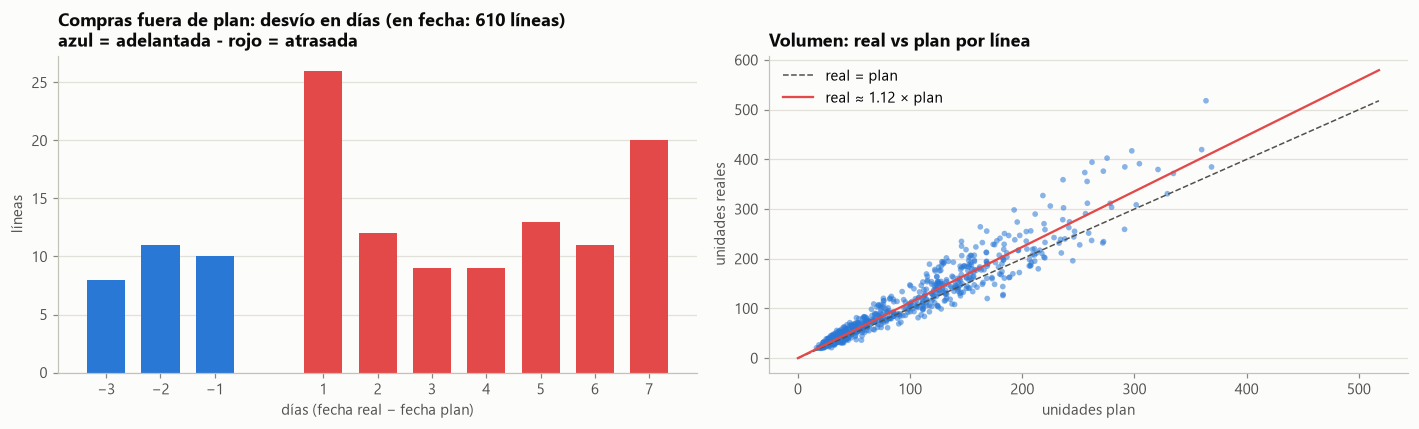

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
off = dist.drop(0, errors="ignore")
ax.bar(off.index, off.values, color=[COLORS["sobre"] if d < 0 else COLORS["sub"] for d in off.index], width=0.7)
ax.set_xticks(off.index)
ax.set_title(f"Compras fuera de plan: desvío en días (en fecha: {dist.get(0,0)} líneas)\n{COLORS['sobre_name']} = adelantada - {COLORS['sub_name']} = atrasada")
ax.set_xlabel("días (fecha real − fecha plan)"); ax.set_ylabel("líneas")

ax = axes[1]
ax.scatter(dp["unidades_plan"], dp["unidades_reales"], s=14, alpha=0.55, color=COLORS["modelo"], edgecolor="none")
m = dp[["unidades_plan", "unidades_reales"]].max().max()
ax.plot([0, m], [0, m], color=COLORS["ink2"], lw=1, ls="--", label="real = plan")
k = dp["unidades_reales"].sum() / dp["unidades_plan"].sum()
ax.plot([0, m], [0, m * k], color=COLORS["sub"], lw=1.5, label=f"real ≈ {k:.2f} × plan")
ax.set_xlabel("unidades plan"); ax.set_ylabel("unidades reales"); ax.legend()
ax.set_title("Volumen: real vs plan por línea")
fig.tight_layout(); save(fig, "t2_bias_plan"); plt.show()

In [10]:
pt = pb_total.iloc[0]
display(Markdown(f'''
**Respuesta 2.1 - ¿Existe bias en el plan? Sí, en ambas dimensiones.**
- **Volumen:** el plan **subestima** sistemáticamente la compra real: bias = **{pt.bias_volumen:+.1%}** (real ≈ {k:.2f}× plan).
  El {pt.pct_lineas_real_mayor_plan:.0%} de las líneas compra más de lo planificado y el sesgo es positivo en **los 6 CD** ({pb_cd.bias_volumen.min():+.1%} a {pb_cd.bias_volumen.max():+.1%}) y en los 3 canales.
- **Fecha:** cuando el cliente se sale del plan, tiende a **atrasarse**: {pt.pct_atrasadas:.1%} de las líneas se atrasan vs {pt.pct_adelantadas:.1%} que se adelantan
  (desvío medio de las fuera de plan: {pt.desvio_dias_medio_fuera_plan:+.1f} días; hay atrasos de hasta 7 días = cliente que "salta" una semana).
- Implicancia: un plan que subestima volumen y asume puntualidad **traslada carga a días no planificados** -> reprogramaciones y fletes no previstos.
'''))


**Respuesta 2.1 - ¿Existe bias en el plan? Sí, en ambas dimensiones.**
- **Volumen:** el plan **subestima** sistemáticamente la compra real: bias = **+10.6%** (real ≈ 1.12× plan).
  El 71% de las líneas compra más de lo planificado y el sesgo es positivo en **los 6 CD** (+8.2% a +14.1%) y en los 3 canales.
- **Fecha:** cuando el cliente se sale del plan, tiende a **atrasarse**: 13.5% de las líneas se atrasan vs 3.9% que se adelantan
  (desvío medio de las fuera de plan: +2.5 días; hay atrasos de hasta 7 días = cliente que "salta" una semana).
- Implicancia: un plan que subestima volumen y asume puntualidad **traslada carga a días no planificados** -> reprogramaciones y fletes no previstos.


### 2.2 Porcentaje de compras fuera de plan - total, por CD y por día de la semana planificado

,lineas,fuera_de_plan,pct_fuera_plan,pct_unidades_fuera_plan
Total,739,129,17.5%,21.1%


,lineas,fuera_de_plan,pct_fuera_plan,pct_unidades_fuera_plan
centro_distribucion,,,,
CD_NORTE,123,30,24.4%,28.2%
CD_PACIFICO,122,26,21.3%,20.4%
CD_ESTE,118,23,19.5%,22.0%
CD_SUR,122,23,18.9%,19.7%
CD_CENTRO,126,14,11.1%,12.7%
CD_OESTE,128,13,10.2%,12.7%


,lineas,fuera_de_plan,pct_fuera_plan,pct_unidades_fuera_plan
dow_plan,,,,
Lunes,104,23,22.1%,25.6%
Martes,259,42,16.2%,13.6%
Miércoles,109,25,22.9%,32.1%
Jueves,151,21,13.9%,17.3%
Viernes,116,18,15.5%,25.3%


,lineas,fuera_de_plan,pct_fuera_plan,pct_unidades_fuera_plan
canal_venta,,,,
AGENTE_COMERCIAL,173,29,16.8%,18.3%
ATENCION_TELEFONICA,131,21,16.0%,15.8%
PORTAL_WEB,435,79,18.2%,23.2%


% fuera de plan por CD × día planificado


dow_plan,Lunes,Martes,Miércoles,Jueves,Viernes
centro_distribucion,,,,,
CD_CENTRO,12%,10%,12%,11%,11%
CD_ESTE,12%,26%,20%,0%,0%
CD_NORTE,0%,18%,33%,11%,33%
CD_OESTE,25%,4%,12%,9%,11%
CD_PACIFICO,29%,18%,0%,27%,22%
CD_SUR,31%,6%,33%,24%,8%


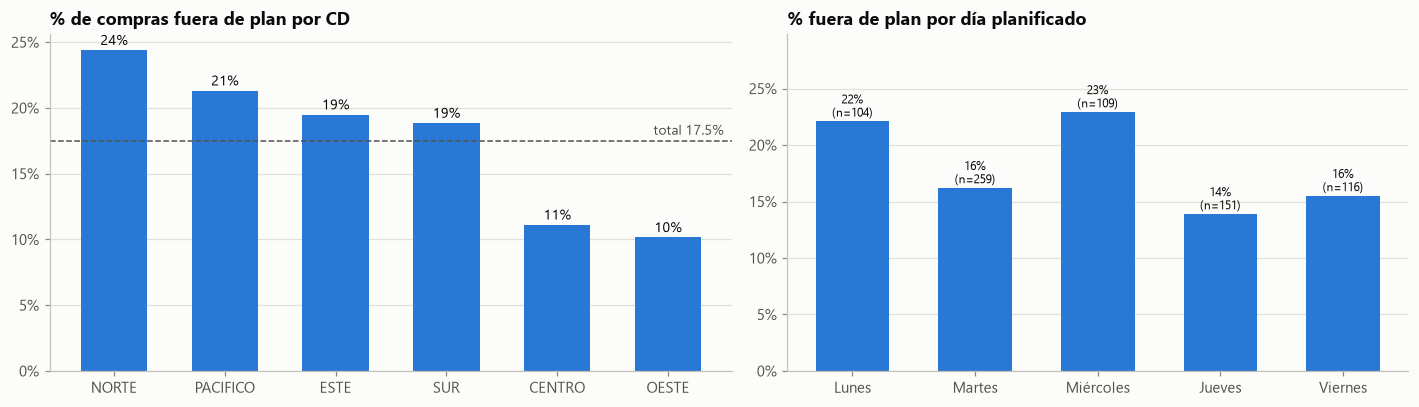

In [11]:
op_total = P.off_plan_rate(dp)
op_cd = P.off_plan_rate(dp, "centro_distribucion").sort_values("pct_fuera_plan", ascending=False)
op_dow = P.off_plan_rate(dp, "dow_plan")
op_canal = P.off_plan_rate(dp, "canal_venta")
op_cd_dow = dp.pivot_table(index="centro_distribucion", columns="dow_plan", values="fuera_de_plan", aggfunc="mean", observed=True)
fmt_op = {"pct_fuera_plan": "{:.1%}", "pct_unidades_fuera_plan": "{:.1%}", "lineas": "{:.0f}", "fuera_de_plan": "{:.0f}"}
for t in (op_total, op_cd, op_dow, op_canal):
    display(t.style.format(fmt_op))
print("% fuera de plan por CD × día planificado"); display(op_cd_dow.style.format("{:.0%}", na_rep="–").background_gradient(cmap=COLORS["cmap_seq2"], axis=None))
pd.concat({"total": op_total, "cd": op_cd, "dow_plan": op_dow, "canal": op_canal}).to_csv(OUTPUT_DIR / "t2_fuera_de_plan.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
ax.bar(op_cd.index.str.replace("CD_", ""), op_cd["pct_fuera_plan"], color=COLORS["modelo"], width=0.6)
ax.axhline(op_total["pct_fuera_plan"].iat[0], color=COLORS["ink2"], ls="--", lw=1)
ax.text(len(op_cd) - 0.5, op_total["pct_fuera_plan"].iat[0] + 0.005, f"total {op_total['pct_fuera_plan'].iat[0]:.1%}", ha="right", color=COLORS["ink2"], fontsize=9)
for x, v in enumerate(op_cd["pct_fuera_plan"]): ax.text(x, v + 0.004, f"{v:.0%}", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(pct); ax.set_title("% de compras fuera de plan por CD")
ax = axes[1]
ax.bar(op_dow.index.astype(str), op_dow["pct_fuera_plan"], color=COLORS["modelo"], width=0.6)
for x, (v, n) in enumerate(zip(op_dow["pct_fuera_plan"], op_dow["lineas"])): ax.text(x, v + 0.004, f"{v:.0%}\n(n={n:.0f})", ha="center", fontsize=8)
ax.yaxis.set_major_formatter(pct); ax.set_title("% fuera de plan por día planificado"); ax.set_ylim(0, op_dow["pct_fuera_plan"].max() * 1.3)
fig.tight_layout(); save(fig, "t2_fuera_de_plan"); plt.show()

In [12]:
from scipy.stats import chi2_contingency
tab_cd = pd.crosstab(dp["centro_distribucion"], dp["fuera_de_plan"]); p_cd = chi2_contingency(tab_cd)[1]
tab_dow = pd.crosstab(dp["dow_plan"], dp["fuera_de_plan"]); p_dow = chi2_contingency(tab_dow)[1]
tab_canal = pd.crosstab(dp["canal_venta"], dp["fuera_de_plan"]); p_canal = chi2_contingency(tab_canal)[1]
display(Markdown(f'''
**Respuesta 2.2**
- **Total:** {op_total['pct_fuera_plan'].iat[0]:.1%} de las compras ({op_total['fuera_de_plan'].iat[0]:.0f} de {op_total['lineas'].iat[0]:.0f} líneas) ocurre fuera de la fecha planificada ({op_total['pct_unidades_fuera_plan'].iat[0]:.1%} de las unidades).
- **Por CD:** rango de {op_cd['pct_fuera_plan'].min():.0%} ({op_cd['pct_fuera_plan'].idxmin()}) a {op_cd['pct_fuera_plan'].max():.0%} ({op_cd['pct_fuera_plan'].idxmax()}) - diferencia significativa (χ² p = {p_cd:.3f}).
  NORTE y PACÍFICO duplican la tasa de CENTRO y OESTE -> la adhesión es un problema **local**, no del sistema.
- **Por día planificado:** {", ".join(f"{d} {v:.0%}" for d, v in op_dow['pct_fuera_plan'].items())} (χ² p = {p_dow:.2f}).
  El martes concentra el {op_dow.loc['Martes','lineas']/op_dow['lineas'].sum():.0%} de las líneas planificadas: aunque su tasa no sea la mayor, es el día que más **volumen absoluto** de desvíos genera.
- **Por canal:** diferencias pequeñas y no significativas (χ² p = {p_canal:.2f}) -> el canal no explica la desadherencia.
'''))


**Respuesta 2.2**
- **Total:** 17.5% de las compras (129 de 739 líneas) ocurre fuera de la fecha planificada (21.1% de las unidades).
- **Por CD:** rango de 10% (CD_OESTE) a 24% (CD_NORTE) - diferencia significativa (χ² p = 0.015).
  NORTE y PACÍFICO duplican la tasa de CENTRO y OESTE -> la adhesión es un problema **local**, no del sistema.
- **Por día planificado:** Lunes 22%, Martes 16%, Miércoles 23%, Jueves 14%, Viernes 16% (χ² p = 0.22).
  El martes concentra el 35% de las líneas planificadas: aunque su tasa no sea la mayor, es el día que más **volumen absoluto** de desvíos genera.
- **Por canal:** diferencias pequeñas y no significativas (χ² p = 0.82) -> el canal no explica la desadherencia.


### 2.3 Métricas adicionales para completar el panorama operativo
| Métrica | Qué responde | Por qué aporta |
|---|---|---|
| **Adhesión al plan por cliente** (1 - % fuera de plan) | ¿Quién rompe el plan? | Permite segmentar clientes (confiables / flexibles / erráticos) y focalizar acciones; el promedio esconde la heterogeneidad |
| **Variación de fecha** (media de \|días\|, % atrasos vs adelantos) | ¿Cuánto y hacia dónde se mueve? | Un atraso de 1 día se absorbe; uno de 7 días es una visita perdida. El signo indica si hay que reservar holgura antes o después |
| **Variación de volumen** (bias y WAPE plan vs real por cliente) | ¿El plan dimensiona bien el pedido? | El bias de volumen impacta directo en la ocupación del camión y en la capacidad del CD |
| **Concentración de desvíos** (Pareto / Gini por cliente) | ¿Pocos clientes generan la mayoría del problema? | Si está concentrado, se ataca con gestión comercial 1:1; si es difuso, con reglas de sistema |
| **Participación del día pico** (share martes plan vs real) y **ratio pico/promedio** | ¿Cuán puntiaguda es la curva? | Es el KPI objetivo del aplanamiento |
| **Utilización vs capacidad** (p95, días > 100%) | ¿Dónde duele? | Conecta el desvío comercial con el costo logístico (fletes de emergencia) |

,count,mean,std,min,25%,50%,75%,max
adhesion_fecha,90.000,0.824,0.178,0.333,0.714,0.875,1.000,1.000
desvio_dias_abs_medio,90.000,0.597,0.749,0.000,0.000,0.250,1.111,3.500
bias_volumen,90.000,0.104,0.090,-0.099,0.037,0.082,0.188,0.268
wape_volumen,90.000,0.153,0.057,0.048,0.108,0.142,0.205,0.268


,clientes,unidades,adhesion_media,pct_unidades
segmento,,,,
Errático (<60%),10,"10,694.170",0.469,0.135
Flexible (60–85%),26,"25,631.930",0.703,0.325
Confiable (>85%),54,"42,604.320",0.949,0.540


Clientes con => 1 compra fuera de plan: 66%
Top 20% clientes explican 68% de las unidades fuera de plan - 80% de las unidades fuera de plan lo explica el 30% de los clientes - Gini = 0.68
Correlación (Spearman) adhesión vs volumen cliente: -0.16


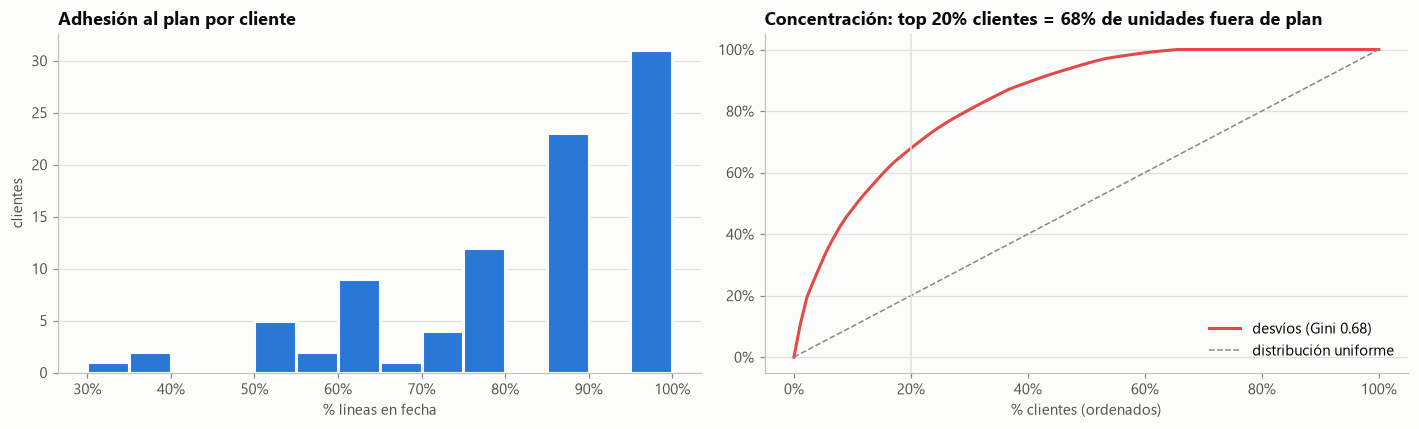

In [13]:
cm = P.client_metrics(dp)
seg = pd.cut(cm["adhesion_fecha"], [-0.01, 0.6, 0.85, 1.0], labels=["Errático (<60%)", "Flexible (60–85%)", "Confiable (>85%)"])
cm["segmento"] = seg
display(cm.describe()[["adhesion_fecha", "desvio_dias_abs_medio", "bias_volumen", "wape_volumen"]].T)
seg_tab = cm.groupby("segmento", observed=True).agg(clientes=("cliente_id", "count"), unidades=("unidades_reales", "sum"), adhesion_media=("adhesion_fecha", "mean"))
seg_tab["pct_unidades"] = seg_tab["unidades"] / seg_tab["unidades"].sum()
display(seg_tab)

# Concentración: ¿qué % de clientes explica el X% de las compras fuera de plan (en unidades)?
off_units = dp.loc[dp["fuera_de_plan"] == 1].groupby("cliente_id")["unidades_reales"].sum().reindex(cm["cliente_id"], fill_value=0)
curve, gini = P.concentration_curve(off_units)
top20 = curve.loc[curve["pct_clientes"] <= 0.2, "pct_acumulado"].max()
clients_with_off = (off_units > 0).mean()
pct_cli_80 = curve.loc[curve["pct_acumulado"] >= 0.8, "pct_clientes"].min()
print(f"Clientes con => 1 compra fuera de plan: {clients_with_off:.0%}")
print(f"Top 20% clientes explican {top20:.0%} de las unidades fuera de plan - 80% de las unidades fuera de plan lo explica el {pct_cli_80:.0%} de los clientes - Gini = {gini:.2f}")

# Correlación adhesión vs volumen (¿los grandes son menos adherentes?)
print("Correlación (Spearman) adhesión vs volumen cliente:", round(cm[["adhesion_fecha", "unidades_reales"]].corr("spearman").iloc[0, 1], 2))
cm.to_csv(OUTPUT_DIR / "t2_metricas_cliente.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.hist(cm["adhesion_fecha"], bins=np.linspace(0.3, 1.0, 15), color=COLORS["modelo"], edgecolor=COLORS["surface"], linewidth=2)
ax.xaxis.set_major_formatter(pct); ax.set_title("Adhesión al plan por cliente"); ax.set_xlabel("% líneas en fecha"); ax.set_ylabel("clientes")
ax = axes[1]
ax.plot(np.r_[0, curve["pct_clientes"]], np.r_[0, curve["pct_acumulado"]], color=COLORS["sub"], label=f"desvíos (Gini {gini:.2f})")
ax.plot([0, 1], [0, 1], color=COLORS["muted"], ls="--", lw=1, label="distribución uniforme")
ax.axvline(0.2, color=COLORS["grid"], lw=1)
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct); ax.legend(loc="lower right")
ax.set_title(f"Concentración: top 20% clientes = {top20:.0%} de unidades fuera de plan"); ax.set_xlabel("% clientes (ordenados)")
fig.tight_layout(); save(fig, "t2_adhesion_concentracion"); plt.show()

### 2.4 Estrategia de aplanamiento de la curva (pico de los martes)

Primero se cuantifica el pico real y su impacto en capacidad; luego se simula la palanca propuesta.

In [14]:
load = P.load_profile(actuals, pkg.capacidad)
prof = P.weekly_profile(load)   # promedios por día (no sumas: hay 9 jueves y 8 martes en 60 días)
display(prof.style.format({"demanda_media": "{:,.0f}", "capacidad_media": "{:,.0f}", "n_dias": "{:.0f}", "indice_vs_promedio": "{:.2f}",
                           "utilizacion": "{:.0%}", "dias_cd_sobre_capacidad": "{:.0f}"}))
cap_cd = load.groupby("centro_distribucion").agg(
    dias_sobre_capacidad=("exceso", lambda s: int((s > 0).sum())), unidades_sobre_capacidad=("exceso", "sum"),
    utilizacion_media=("utilizacion", "mean"), utilizacion_p95=("utilizacion", lambda s: s.quantile(0.95)),
    utilizacion_martes=("utilizacion", lambda s: s[load.loc[s.index, "dow"] == 1].mean()),
).sort_values("dias_sobre_capacidad", ascending=False)
print("Capacidad por CD"); display(cap_cd.style.format({"unidades_sobre_capacidad": "{:,.0f}", "utilizacion_media": "{:.0%}", "utilizacion_p95": "{:.0%}", "utilizacion_martes": "{:.0%}"}))
cap_cd.to_csv(OUTPUT_DIR / "t2_capacidad_por_cd.csv")

share_plan_tue = (dp["dow_plan"] == "Martes").mean(); share_real_tue = (dp["dow_real"] == "Martes").mean()
print(f"Share martes - líneas del plan: {share_plan_tue:.0%} - compras reales: {share_real_tue:.0%} - demanda CD: {prof.loc['Martes','demanda_media']/prof['demanda_media'].sum():.0%} (1/7 = 14%)")
mig = P.day_migration(dp)
print("Migración día planificado -> día real (solo compras fuera de plan):"); display(mig)
pct_off_to_tue = mig.loc["Total", "Martes"] / mig.loc["Total", "Total"]
pct_off_tue_from_other = mig.loc["Total", "Martes"] - mig.loc["Martes", "Martes"]
pool = P.shiftable_tuesday_volume(dp); display(pool.to_frame("valor").T)

,demanda_media,capacidad_media,n_dias,indice_vs_promedio,utilizacion,dias_cd_sobre_capacidad
Lunes,"8,564","10,380",8,0.97,83%,1
Martes,"10,923","12,975",8,1.24,84%,4
Miércoles,"8,726","10,380",8,0.99,84%,3
Jueves,"8,622","10,380",9,0.98,83%,1
Viernes,"8,813","10,380",9,1.00,85%,3
Sábado,"8,600","10,380",9,0.98,83%,1
Domingo,"7,274","10,380",9,0.83,70%,0


Capacidad por CD


,dias_sobre_capacidad,unidades_sobre_capacidad,utilizacion_media,utilizacion_p95,utilizacion_martes
centro_distribucion,,,,,
CD_NORTE,6,974,83%,102%,81%
CD_CENTRO,2,122,81%,99%,84%
CD_SUR,2,354,81%,96%,90%
CD_ESTE,1,70,80%,95%,83%
CD_OESTE,1,11,79%,94%,83%
CD_PACIFICO,1,8,82%,94%,87%


Share martes - líneas del plan: 35% - compras reales: 40% - demanda CD: 18% (1/7 = 14%)
Migración día planificado -> día real (solo compras fuera de plan):


dow_real,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado,Domingo,Total
dow_plan,,,,,,,,
Lunes,0,16,3,1,1,1,1,23
Martes,3,20,7,2,1,4,5,42
Miércoles,1,16,0,2,2,3,1,25
Jueves,1,15,1,0,1,1,2,21
Viernes,2,10,2,0,0,0,4,18
Total,7,77,13,5,5,9,13,129


,unidades_plan_martes,unidades_martes_clientes_flexibles,pct_martes_flexible,clientes_flexibles,clientes_totales
valor,"23,288.430","14,907.340",0.640,59.000,90.000


,ratio_pico_promedio_dow,participacion_martes,cv_diario_medio,dias_cd_sobre_capacidad,unidades_sobre_capacidad,utilizacion_p95,pct_volumen_movido
Actual,1.24,17.8%,0.156,13,"1,540",98%,0.0%
Estático: mover 5% del martes,1.18,16.9%,0.138,11,"1,310",97%,0.8%
Estático: mover 10% del martes,1.12,16.0%,0.126,9,"1,350",97%,1.7%
Estático: mover 15% del martes,1.06,15.1%,0.119,11,"1,550",98%,2.5%
Estático: mover 20% del martes,1.07,14.2%,0.118,13,"1,821",99%,3.3%
Estático: mover 30% del martes,1.11,12.5%,0.134,22,"2,790",101%,5.0%
Dinámico: slotting por utilización (≤90%),1.23,17.5%,0.130,0,0,90%,1.6%
Combinado: 10% martes + dinámico,1.15,16.4%,0.108,0,0,90%,2.7%


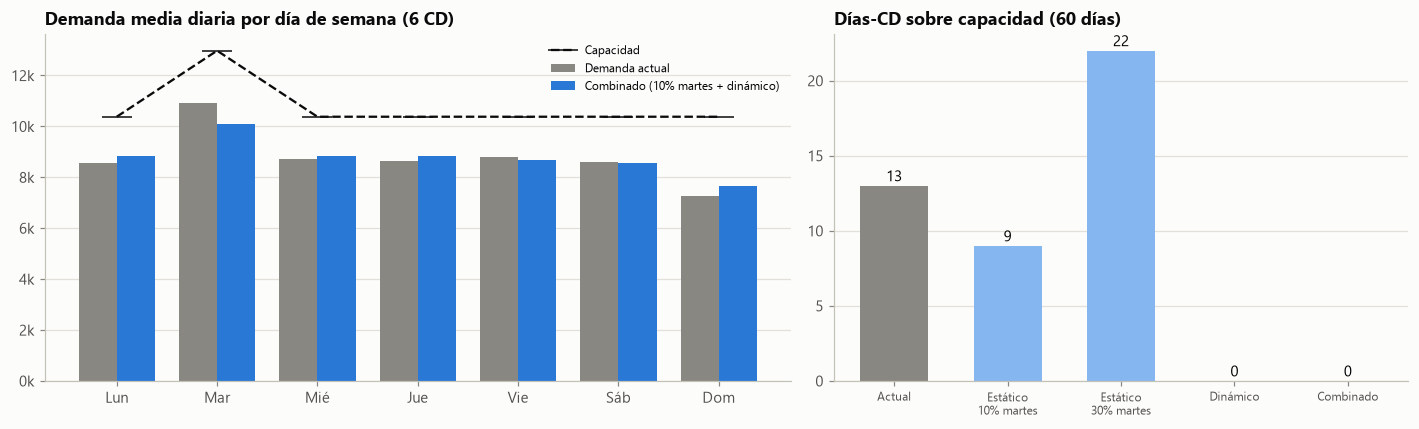

In [15]:
scen = {"Actual": load.assign(sim=load["real"])}
for s in [0.05, 0.10, 0.15, 0.20, 0.30]:
    scen[f"Estático: mover {s:.0%} del martes"] = P.simulate_peak_shift(load, s)
scen["Dinámico: slotting por utilización (≤90%)"] = P.simulate_dynamic_slotting(load, max_util=0.90, flex_share=0.20)
pre = P.simulate_peak_shift(load, 0.10)
scen["Combinado: 10% martes + dinámico"] = P.simulate_dynamic_slotting(pre.drop(columns="real").rename(columns={"sim": "real"}), 0.90, 0.20).assign(real=load["real"].values)
rows = {}
for k, sdf in scen.items():
    kp = P.peak_kpis(sdf, col="sim")
    kp["pct_volumen_movido"] = (sdf["sim"] - sdf["real"]).clip(lower=0).sum() / sdf["real"].sum()
    rows[k] = kp
kpi_flat = pd.DataFrame(rows).T
display(kpi_flat.style.format({"ratio_pico_promedio_dow": "{:.2f}", "participacion_martes": "{:.1%}", "cv_diario_medio": "{:.3f}",
                               "dias_cd_sobre_capacidad": "{:.0f}", "unidades_sobre_capacidad": "{:,.0f}", "utilizacion_p95": "{:.0%}",
                               "pct_volumen_movido": "{:.1%}"}).highlight_min(["cv_diario_medio", "dias_cd_sobre_capacidad"], color=COLORS["highlight"]))
kpi_flat.to_csv(OUTPUT_DIR / "t2_simulacion_aplanamiento.csv")
BEST_STATIC = kpi_flat.filter(like="Estático", axis=0)["ratio_pico_promedio_dow"].idxmin()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
xs = np.arange(7); wbar = 0.38
comb = P.weekly_profile(scen["Combinado: 10% martes + dinámico"], "sim")
ax.bar(xs - wbar/2, prof["demanda_media"], width=wbar, color=COLORS["base"], label="Demanda actual")
ax.bar(xs + wbar/2, comb["demanda_media"], width=wbar, color=COLORS["modelo"], label="Combinado (10% martes + dinámico)")
ax.plot(xs, prof["capacidad_media"], color=COLORS["capacidad"], lw=1.5, ls="--", marker="_", ms=20, label="Capacidad")
ax.set_xticks(xs, [d[:3] for d in DIAS_SEMANA]); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.set_title("Demanda media diaria por día de semana (6 CD)"); ax.legend(ncol=1, fontsize=8, loc="upper right")
ax = axes[1]
lab = ["Actual", "Estático\n10% martes", "Estático\n30% martes", "Dinámico", "Combinado"]
keys = ["Actual", "Estático: mover 10% del martes", "Estático: mover 30% del martes", "Dinámico: slotting por utilización (≤90%)", "Combinado: 10% martes + dinámico"]
vals = kpi_flat.loc[keys, "dias_cd_sobre_capacidad"]
ax.bar(lab, vals, color=[COLORS["base"], COLORS["light"], COLORS["light"], COLORS["modelo"], COLORS["modelo"]], width=0.6)
for x, v in enumerate(vals): ax.text(x, v + 0.3, f"{v:.0f}", ha="center", fontsize=10)
ax.set_title("Días-CD sobre capacidad (60 días)"); ax.tick_params(axis="x", labelsize=8)
fig.tight_layout(); save(fig, "t2_aplanamiento"); plt.show()

In [16]:
k0 = kpi_flat.loc["Actual"]; ks = kpi_flat.loc[BEST_STATIC]; k30 = kpi_flat.loc["Estático: mover 30% del martes"]
kd = kpi_flat.loc["Dinámico: slotting por utilización (≤90%)"]; kc = kpi_flat.loc["Combinado: 10% martes + dinámico"]
display(Markdown(f'''
**Respuesta 2.4 - Estrategia: "fecha de despacho recomendada" consciente de capacidad + incentivo para salir del martes**

*Diagnóstico*
- La demanda media del martes es **{prof.loc['Martes','indice_vs_promedio']:.2f}×** el promedio diario; el {share_plan_tue:.0%} de las líneas del plan cae en martes.
- **El pico se auto-refuerza:** de las {mig.loc['Total','Total']} compras fuera de plan, **{pct_off_to_tue:.0%} terminan comprándose en martes** ({pct_off_tue_from_other} vienen de otros días planificados).
  La desadherencia no es aleatoria: los clientes "vuelven" a su día preferido.
- La capacidad del martes ya es +25%, por eso la utilización media del martes ({prof.loc['Martes','utilizacion']:.0%}) es similar al resto. Los problemas están en los **días puntuales sobre capacidad**: {k0.dias_cd_sobre_capacidad:.0f} días-CD
  ({prof.loc['Martes','dias_cd_sobre_capacidad']:.0f} en martes, el resto en otros días), concentrados en **{cap_cd.index[0]}** ({cap_cd.iloc[0]['dias_sobre_capacidad']:.0f} días).

*Simulación (el volumen se mueve, no se pierde)*
- **Palanca estática** (mover un % fijo del martes a lun/mié/jue): el óptimo es pequeño. El pico/promedio mínimo se logra al **{BEST_STATIC.split(': ')[1]}** ({k0.ratio_pico_promedio_dow:.2f} -> {ks.ratio_pico_promedio_dow:.2f}),
  pero los días sobre capacidad se minimizan con **10%** ({k0.dias_cd_sobre_capacidad:.0f} -> {kpi_flat.loc['Estático: mover 10% del martes','dias_cd_sobre_capacidad']:.0f}): mover más carga a lunes/miércoles, que tienen 20% menos capacidad que el martes.
  Moverlo de más es contraproducente: con 30% se *crean* nuevos picos ({k30.dias_cd_sobre_capacidad:.0f} días-CD sobre capacidad).
- **Palanca dinámica** (recomendar ±2 días cuando la utilización proyectada supera 90%, con un tope del 20% del volumen del día): elimina los días sobre capacidad ({k0.dias_cd_sobre_capacidad:.0f} -> {kd.dias_cd_sobre_capacidad:.0f})
  moviendo solo el **{kd.pct_volumen_movido:.1%}** del volumen total.
- **Combinado** (incentivo de 10% fuera del martes + slotting dinámico): pico/promedio {kc.ratio_pico_promedio_dow:.2f}, CV diario {k0.cv_diario_medio:.3f} -> {kc.cv_diario_medio:.3f}, {kc.dias_cd_sobre_capacidad:.0f} días sobre capacidad, moviendo {kc.pct_volumen_movido:.1%} del volumen.

*Mecanismo propuesto*
1. **Utilización proyectada por slot:** al tomar el pedido, para cada fecha candidata (D+1…D+4) se calcula pronóstico **corregido** (Tarea 3) / capacidad. Sin un pronóstico corregido esta palanca no funciona: con el base, SUR y ESTE se verían con holgura que no existe.
2. **Recomendación ordenada por holgura + incentivo:** se ofrece por defecto el slot de menor utilización dentro de la ventana del cliente; si el cliente elige un slot > 90%, se le muestra un incentivo (descuento logístico, prioridad de entrega, menor pedido mínimo) por moverse. El martes no se prohíbe.
3. **Segmentación:** se empieza por los {pool['clientes_flexibles']:.0f} de {pool['clientes_totales']:.0f} clientes que ya demostraron flexibilidad (≥1 compra fuera de plan), que tienen el {pool['pct_martes_flexible']:.0%} del volumen del martes: alcanza para el 10% sin tocar a los clientes rígidos.
4. **Plan corregido por bias:** el plan de entrega se dimensiona con el bias de volumen observado (+{pt.bias_volumen:.0%}) para no subdimensionar los días receptores.

*Implementación:* A/B test aleatorizado por cliente (estratificado por CD y segmento), 4-6 semanas; umbral de utilización e incentivo configurables por CD; guardarraíl: nunca recomendar un slot con utilización proyectada > 95%.

*KPIs*
- **Primario:** % días-CD sobre capacidad y unidades sobre capacidad (-> fletes de emergencia).
- **Forma de la curva:** ratio pico/promedio por día de semana, CV de la carga diaria, participación del martes.
- **Adopción:** tasa de aceptación de la fecha recomendada, % volumen movido, costo del incentivo por unidad movida.
- **Guardarraíles:** OTIF, volumen total por cliente (que el incentivo no genere pérdida de venta) y adhesión al plan.
'''))


**Respuesta 2.4 - Estrategia: "fecha de despacho recomendada" consciente de capacidad + incentivo para salir del martes**

*Diagnóstico*
- La demanda media del martes es **1.24×** el promedio diario; el 35% de las líneas del plan cae en martes.
- **El pico se auto-refuerza:** de las 129 compras fuera de plan, **60% terminan comprándose en martes** (57 vienen de otros días planificados).
  La desadherencia no es aleatoria: los clientes "vuelven" a su día preferido.
- La capacidad del martes ya es +25%, por eso la utilización media del martes (84%) es similar al resto. Los problemas están en los **días puntuales sobre capacidad**: 13 días-CD
  (4 en martes, el resto en otros días), concentrados en **CD_NORTE** (6 días).

*Simulación (el volumen se mueve, no se pierde)*
- **Palanca estática** (mover un % fijo del martes a lun/mié/jue): el óptimo es pequeño. El pico/promedio mínimo se logra al **mover 15% del martes** (1.24 -> 1.06),
  pero los días sobre capacidad se minimizan con **10%** (13 -> 9): mover más carga a lunes/miércoles, que tienen 20% menos capacidad que el martes.
  Moverlo de más es contraproducente: con 30% se *crean* nuevos picos (22 días-CD sobre capacidad).
- **Palanca dinámica** (recomendar ±2 días cuando la utilización proyectada supera 90%, con un tope del 20% del volumen del día): elimina los días sobre capacidad (13 -> 0)
  moviendo solo el **1.6%** del volumen total.
- **Combinado** (incentivo de 10% fuera del martes + slotting dinámico): pico/promedio 1.15, CV diario 0.156 -> 0.108, 0 días sobre capacidad, moviendo 2.7% del volumen.

*Mecanismo propuesto*
1. **Utilización proyectada por slot:** al tomar el pedido, para cada fecha candidata (D+1…D+4) se calcula pronóstico **corregido** (Tarea 3) / capacidad. Sin un pronóstico corregido esta palanca no funciona: con el base, SUR y ESTE se verían con holgura que no existe.
2. **Recomendación ordenada por holgura + incentivo:** se ofrece por defecto el slot de menor utilización dentro de la ventana del cliente; si el cliente elige un slot > 90%, se le muestra un incentivo (descuento logístico, prioridad de entrega, menor pedido mínimo) por moverse. El martes no se prohíbe.
3. **Segmentación:** se empieza por los 59 de 90 clientes que ya demostraron flexibilidad (≥1 compra fuera de plan), que tienen el 64% del volumen del martes: alcanza para el 10% sin tocar a los clientes rígidos.
4. **Plan corregido por bias:** el plan de entrega se dimensiona con el bias de volumen observado (+11%) para no subdimensionar los días receptores.

*Implementación:* A/B test aleatorizado por cliente (estratificado por CD y segmento), 4-6 semanas; umbral de utilización e incentivo configurables por CD; guardarraíl: nunca recomendar un slot con utilización proyectada > 95%.

*KPIs*
- **Primario:** % días-CD sobre capacidad y unidades sobre capacidad (-> fletes de emergencia).
- **Forma de la curva:** ratio pico/promedio por día de semana, CV de la carga diaria, participación del martes.
- **Adopción:** tasa de aceptación de la fecha recomendada, % volumen movido, costo del incentivo por unidad movida.
- **Guardarraíles:** OTIF, volumen total por cliente (que el incentivo no genere pérdida de venta) y adhesión al plan.


## 3. Tarea 3 - Modelo complementario de forecast

### 3.1 Diseño
- **Unidad de predicción:** cada pronóstico emitido (CD, fecha de emisión E, fecha objetivo D, horizonte h).
- **Target:** `log(real / pronóstico_base)` -> el modelo aprende **la corrección** del base, no la demanda desde cero.
  Es invariante a la escala del CD (un solo modelo para los 6 CD, sin identificador de CD -> transferible a CDs nuevos) y la predicción final es `base × exp(ŷ)`.
- **Regla anti-fuga:** con emisión en E solo se usa demanda real hasta E-1 y errores de pronósticos ya realizados (D ≤ E-1).

| Grupo | Features |
|---|---|
| Calendario | día de la semana (sin/cos), `es_martes` |
| Indicadores de pico | `es_dia_pico` (DOW con mayor demanda media en la historia conocida a E), índice estacional del DOW (media mismo DOW 4 sem. / media 28d) |
| Rolling | media 7d y 14d, CV 7d, real del mismo DOW la semana anterior, media del mismo DOW en 4 semanas |
| Sesgo móvil del base | Σreal/Σpronóstico últimos 14 y 28 días (por CD, todos los horizontes) |

**Iteraciones** (se documentan ambas: el notebook se corrió dos veces y la revisión de la primera motivó la segunda)
- **v1 - features en niveles, un modelo global:** Ridge/HGB con las features en unidades y `h` como variable. Resultado: 8.3% WAPE, pero
  peor que la regla simple de sesgo en D+1 y con sesgo −5% en CD_NORTE (un modelo lineal global no puede ponderar distinto por horizonte).
- **v2 - features log-relativas + un modelo por horizonte (campeón):** cada señal histórica entra como `log(señal / pronóstico)`
  (p.ej. `log(media7 / base)`, `log(sesgo14)`), de modo que el Ridge aprende una **combinación ponderada en escala log** entre el base, su sesgo reciente y la historia propia.
  Un modelo por horizonte permite que en D+1 confíe más en el base corregido y en D+4 más en la historia.

In [17]:
feats = build_features(fva.drop(columns=["error", "semana", "dow"]), actuals)
print("Filas:", len(feats), "· % nulos por feature (warm-up de ventanas rolling):")
display(feats[LOG_FEATURE_COLS].isna().mean().to_frame("pct_nulos").T.style.format("{:.0%}"))
display(feats[["centro_distribucion", "fecha_emision", "fecha_despacho", "horizonte", "pronostico", "real"] + LOG_FEATURE_COLS].dropna().head(3))

Filas: 1380 · % nulos por feature (warm-up de ventanas rolling):


,log_sesgo_14,log_sesgo_28,log_media7_vs_pron,log_media14_vs_pron,log_dow4s_vs_pron,log_lag_dow_vs_pron,log_indice_estacional,cv_7,dow_sin,dow_cos,es_martes,es_dia_pico
pct_nulos,14%,26%,9%,17%,8%,8%,24%,9%,0%,0%,0%,24%


,centro_distribucion,fecha_emision,fecha_despacho,horizonte,pronostico,real,log_sesgo_14,log_sesgo_28,log_media7_vs_pron,log_media14_vs_pron,log_dow4s_vs_pron,log_lag_dow_vs_pron,log_indice_estacional,cv_7,dow_sin,dow_cos,es_martes,es_dia_pico
54,CD_CENTRO,2026-01-16,2026-01-17,D+1,"1,824.780","1,475.600",-0.182,-0.182,-0.252,-0.216,-0.205,-0.284,0.009,0.162,-0.975,-0.223,0,0.000
58,CD_CENTRO,2026-01-17,2026-01-18,D+1,"1,627.020","1,413.210",-0.189,-0.190,-0.099,-0.110,-0.321,-0.343,-0.229,0.158,-0.782,0.623,0,0.000
59,CD_CENTRO,2026-01-16,2026-01-18,D+2,"1,517.910","1,413.210",-0.182,-0.182,-0.068,-0.032,-0.251,-0.274,-0.222,0.162,-0.782,0.623,0,0.000


### 3.2 Backtest con origen rodante (rolling-origin, ventana expansiva)
- Orígenes semanales desde el día 21 (22-ene, 29-ene, …, 26-feb) -> **6 folds**.
- En cada origen T: **train** = pronósticos con fecha objetivo < T (real ya observado); **test** = pronósticos **emitidos** en [T, T+7), todos los horizontes.
- Todos los modelos se evalúan sobre **exactamente las mismas filas** y se re-entrenan en cada fold (como lo haría el batch semanal).

In [18]:
CHAMPION = "ML ridge log por horizonte"
V1 = "ML ridge raw global"
factories = [
    BaselineModel,
    lambda: RollingBiasCorrector(14),
    lambda: RollingBiasCorrector(28),
    # v1: features en niveles, modelo global
    lambda: MLCorrector("ridge", feature_set="raw", per_horizon=False),
    lambda: MLCorrector("ridge", feature_set="raw", per_horizon=False, include_cd=True),
    lambda: MLCorrector("hgb", feature_set="raw", per_horizon=False),
    # v2: features log-relativas
    lambda: MLCorrector("ridge", feature_set="log", per_horizon=False),
    lambda: MLCorrector("ridge", feature_set="log", per_horizon=True),
    lambda: MLCorrector("hgb", feature_set="log", per_horizon=False),
    lambda: MLCorrector("hgb", feature_set="log", per_horizon=True),
]
MODEL_NAMES = [f().name for f in factories]
assert CHAMPION in MODEL_NAMES and V1 in MODEL_NAMES
origins = make_origins(feats, first_origin_day=21, step_days=7)
print("Orígenes:", [str(o.date()) for o in origins])
bt = rolling_origin_backtest(feats, factories, origins)
res_global = summarize_backtest(bt, MODEL_NAMES).T.unstack()
res_global.columns = res_global.columns.droplevel(0)
res_global = res_global[["WAPE", "Bias"]]
res_global["mejora_WAPE_vs_base_pp"] = (res_global.loc["Base", "WAPE"] - res_global["WAPE"]) * 100
res_global["mejora_relativa"] = 1 - res_global["WAPE"] / res_global.loc["Base", "WAPE"]
res_global = res_global.loc[MODEL_NAMES]
display(res_global.style.format({"WAPE": "{:.2%}", "Bias": "{:+.2%}", "mejora_WAPE_vs_base_pp": "{:+.1f}", "mejora_relativa": "{:.0%}"}).highlight_min("WAPE", color=COLORS["highlight"]))
res_global.to_csv(OUTPUT_DIR / "t3_backtest_global.csv")

Orígenes: ['2026-01-22', '2026-01-29', '2026-02-05', '2026-02-12', '2026-02-19', '2026-02-26']


,WAPE,Bias,mejora_WAPE_vs_base_pp,mejora_relativa
Base,20.70%,+6.62%,+0.0,0%
Corrección sesgo 14d,9.43%,-0.12%,+11.3,54%
Corrección sesgo 28d,9.42%,-0.09%,+11.3,55%
ML ridge raw global,8.27%,-0.96%,+12.4,60%
ML ridge raw global + CD,8.07%,-0.52%,+12.6,61%
ML hgb raw global,8.21%,-0.76%,+12.5,60%
ML ridge log global,7.38%,+0.29%,+13.3,64%
ML ridge log por horizonte,6.57%,+0.27%,+14.1,68%
ML hgb log global,8.10%,-0.58%,+12.6,61%
ML hgb log por horizonte,8.70%,-0.69%,+12.0,58%


In [19]:
SHOW = ["Base", "Corrección sesgo 14d", V1, "ML hgb log global", CHAMPION]
w_fold = summarize_backtest(bt, MODEL_NAMES, "fold").xs("WAPE", axis=1, level=1)
w_fold.index = [f"F{i} ({o.date():%d-%b})" for i, o in zip(w_fold.index, origins)]
n_test = bt.groupby("fold").size().values
print("WAPE por fold"); display(w_fold[SHOW].assign(n_test=n_test).style.format("{:.1%}", subset=SHOW))
wins = pd.DataFrame({
    "folds_mejor_que_base": (w_fold[MODEL_NAMES].lt(w_fold["Base"], axis=0)).mean(),
    "folds_mejor_que_fallback": (w_fold[MODEL_NAMES].lt(w_fold["Corrección sesgo 14d"], axis=0)).mean(),
}).drop(["Base"])
display(wins.T.style.format("{:.0%}"))

w_cd = summarize_backtest(bt, MODEL_NAMES, "centro_distribucion").xs("WAPE", axis=1, level=1)
w_h = summarize_backtest(bt, MODEL_NAMES, "horizonte").xs("WAPE", axis=1, level=1)
b_cd = summarize_backtest(bt, MODEL_NAMES, "centro_distribucion").xs("Bias", axis=1, level=1)
bt["dow"] = bt["fecha_despacho"].dt.dayofweek
w_dow = summarize_backtest(bt, MODEL_NAMES, "dow").xs("WAPE", axis=1, level=1); w_dow.index = DIAS_SEMANA
print("WAPE por CD"); display(w_cd[SHOW].style.format("{:.1%}").highlight_min(axis=1, color=COLORS["highlight"]))
print("Bias por CD"); display(b_cd[SHOW].style.format("{:+.1%}"))
print("WAPE por horizonte"); display(w_h[SHOW].style.format("{:.1%}").highlight_min(axis=1, color=COLORS["highlight"]))
print("WAPE por día de la semana"); display(w_dow[SHOW].style.format("{:.1%}").highlight_min(axis=1, color=COLORS["highlight"]))
for name, t in {"t3_wape_fold": w_fold, "t3_wape_cd": w_cd, "t3_bias_cd": b_cd, "t3_wape_horizonte": w_h, "t3_wape_dow": w_dow}.items():
    t.to_csv(OUTPUT_DIR / f"{name}.csv")

WAPE por fold


,Base,Corrección sesgo 14d,ML ridge raw global,ML hgb log global,ML ridge log por horizonte,n_test
F0 (22-Jan),20.6%,9.9%,10.9%,10.2%,7.4%,168
F1 (29-Jan),20.7%,9.5%,8.5%,8.6%,6.6%,168
F2 (05-Feb),21.1%,9.3%,6.7%,7.3%,5.9%,168
F3 (12-Feb),20.2%,9.7%,7.9%,8.5%,7.9%,168
F4 (19-Feb),21.0%,9.3%,7.8%,6.4%,5.5%,168
F5 (26-Feb),20.0%,6.0%,5.7%,5.5%,4.6%,36


,Corrección sesgo 14d,Corrección sesgo 28d,ML ridge raw global,ML ridge raw global + CD,ML hgb raw global,ML ridge log global,ML ridge log por horizonte,ML hgb log global,ML hgb log por horizonte
folds_mejor_que_base,100%,100%,100%,100%,100%,100%,100%,100%,100%
folds_mejor_que_fallback,0%,67%,83%,83%,100%,100%,100%,83%,67%


WAPE por CD


,Base,Corrección sesgo 14d,ML ridge raw global,ML hgb log global,ML ridge log por horizonte
centro_distribucion,,,,,
CD_CENTRO,23.1%,12.5%,9.7%,9.0%,8.6%
CD_ESTE,25.4%,15.8%,9.7%,8.5%,7.9%
CD_NORTE,9.6%,7.6%,8.9%,7.9%,6.2%
CD_OESTE,23.3%,8.6%,7.8%,6.1%,5.9%
CD_PACIFICO,22.7%,8.3%,5.5%,6.2%,5.0%
CD_SUR,31.4%,8.0%,6.9%,8.7%,5.9%


...

,Base,Corrección sesgo 14d,ML ridge raw global,ML hgb log global,ML ridge log por horizonte
centro_distribucion,,,,,
CD_CENTRO,-19.8%,+0.6%,+3.4%,-0.8%,-0.6%
CD_ESTE,+24.8%,-0.1%,+2.6%,+3.0%,+2.5%
CD_NORTE,+7.8%,-0.3%,-4.9%,-2.1%,-0.1%
CD_OESTE,-22.0%,-0.4%,-3.4%,-0.8%,-1.1%
CD_PACIFICO,-22.2%,-0.4%,-0.0%,-0.6%,-0.2%
CD_SUR,+31.4%,-0.3%,+0.4%,+0.4%,+1.1%


WAPE por horizonte


,Base,Corrección sesgo 14d,ML ridge raw global,ML hgb log global,ML ridge log por horizonte
horizonte,,,,,
D+1,19.5%,4.0%,6.3%,6.6%,3.8%
D+2,20.1%,7.9%,7.6%,7.7%,6.3%
D+3,20.7%,11.3%,8.4%,8.1%,7.5%
D+4,22.6%,14.9%,10.9%,10.1%,8.9%


WAPE por día de la semana


,Base,Corrección sesgo 14d,ML ridge raw global,ML hgb log global,ML ridge log por horizonte
Lunes,20.1%,9.4%,8.7%,9.5%,7.5%
Martes,20.9%,9.5%,9.6%,9.6%,7.3%
Miércoles,19.0%,9.3%,7.7%,7.3%,6.1%
Jueves,22.7%,10.2%,6.1%,6.8%,4.8%
Viernes,20.0%,8.6%,8.0%,7.2%,6.8%
Sábado,20.6%,9.5%,8.3%,7.2%,6.7%
Domingo,21.6%,9.5%,9.1%,8.9%,6.6%


,ΔWAPE_pp,IC95_inf_pp,IC95_sup_pp,P(champion mejor)
comparación,,,,
ML ridge log por horizonte − Base,-14.14,-15.10,-13.16,100%
ML ridge log por horizonte − Corrección sesgo 14d,-2.84,-3.39,-2.17,100%
ML ridge log por horizonte − ML ridge raw global,-1.72,-2.61,-0.90,100%
ML ridge log por horizonte − ML hgb log global,-1.56,-2.29,-1.02,100%


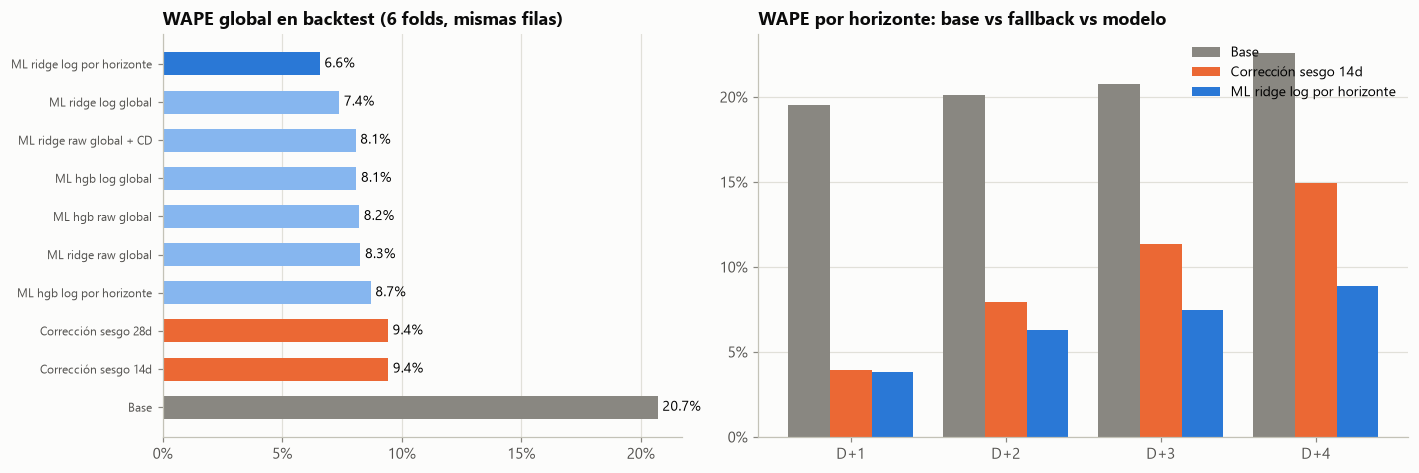

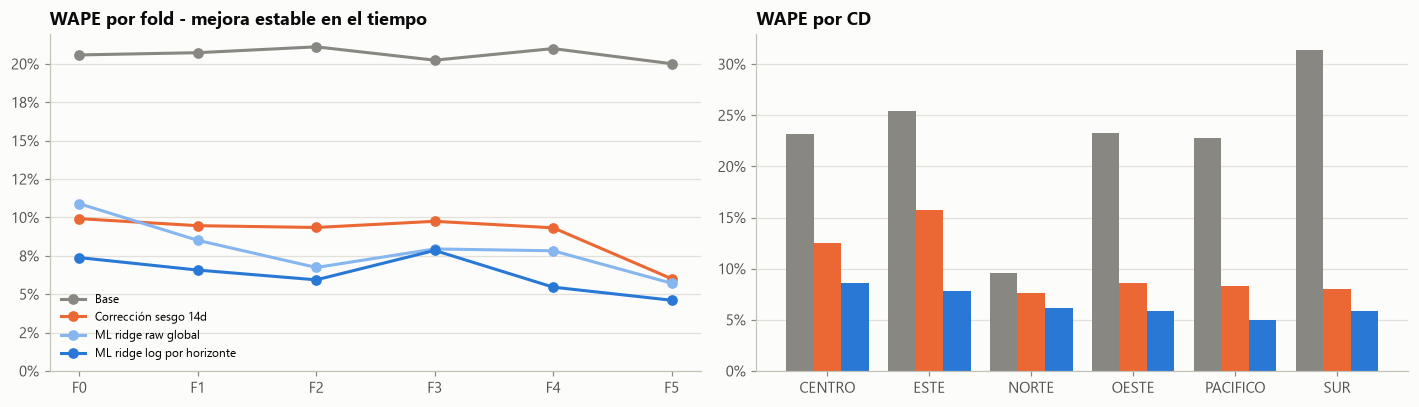

In [20]:
# Significancia: bootstrap por bloques semanales de la diferencia de WAPE
rng = np.random.default_rng(42)
bt["semana"] = bt["fecha_despacho"].dt.to_period("W-SUN")
groups = {wk: d for wk, d in bt.groupby("semana")}
weeks = list(groups)
def boot_diff(a: str, b: str, n: int = 2000) -> np.ndarray:
    out = np.empty(n)
    for k in range(n):
        sample = pd.concat([groups[weeks[i]] for i in rng.integers(0, len(weeks), len(weeks))])
        out[k] = wape(sample["real"], sample[a]) - wape(sample["real"], sample[b])
    return out
boot_rows = []
for ref in ["Base", "Corrección sesgo 14d", V1, "ML hgb log global"]:
    d = boot_diff(CHAMPION, ref)
    boot_rows.append({"comparación": f"{CHAMPION} − {ref}", "ΔWAPE_pp": d.mean() * 100,
                      "IC95_inf_pp": np.percentile(d, 2.5) * 100, "IC95_sup_pp": np.percentile(d, 97.5) * 100, "P(champion mejor)": (d < 0).mean()})
boot = pd.DataFrame(boot_rows).set_index("comparación")
display(boot.style.format({"ΔWAPE_pp": "{:+.2f}", "IC95_inf_pp": "{:+.2f}", "IC95_sup_pp": "{:+.2f}", "P(champion mejor)": "{:.0%}"}))
boot.to_csv(OUTPUT_DIR / "t3_bootstrap.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
order = res_global["WAPE"].sort_values(ascending=False)
cols = [COLORS["base"] if n == "Base" else (COLORS["modelo"] if n == CHAMPION else (COLORS["fallback"] if n.startswith("Corrección") else COLORS["light"])) for n in order.index]
ax.barh(order.index, order.values, color=cols, height=0.6)
for y, v in enumerate(order.values): ax.text(v + 0.002, y, f"{v:.1%}", va="center", fontsize=9)
ax.xaxis.set_major_locator(mtick.MultipleLocator(0.05)); ax.xaxis.set_major_formatter(pct); ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
ax.set_title("WAPE global en backtest (6 folds, mismas filas)")
ax = axes[1]
x = np.arange(4); wb = 0.27
for j, (n, c) in enumerate([("Base", COLORS["base"]), ("Corrección sesgo 14d", COLORS["fallback"]), (CHAMPION, COLORS["modelo"])]):
    ax.bar(x + (j - 1) * wb, w_h[n], width=wb, color=c, label=n)
ax.set_xticks(x, HORIZONTES); ax.yaxis.set_major_formatter(pct)
ax.set_title("WAPE por horizonte: base vs fallback vs modelo"); ax.legend(fontsize=9)
fig.tight_layout(); save(fig, "t3_resultados"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
for n, c in [("Base", COLORS["base"]), ("Corrección sesgo 14d", COLORS["fallback"]), (V1, COLORS["light"]), (CHAMPION, COLORS["modelo"])]:
    ax.plot(range(len(w_fold)), w_fold[n], marker="o", color=c, label=n)
ax.set_xticks(range(len(w_fold)), [s.split(" ")[0] for s in w_fold.index]); ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, None)
ax.set_title("WAPE por fold - mejora estable en el tiempo"); ax.legend(fontsize=8)
ax = axes[1]
x = np.arange(len(w_cd)); wb = 0.27
for j, (n, c) in enumerate([("Base", COLORS["base"]), ("Corrección sesgo 14d", COLORS["fallback"]), (CHAMPION, COLORS["modelo"])]):
    ax.bar(x + (j - 1) * wb, w_cd[n], width=wb, color=c, label=n)
ax.set_xticks(x, w_cd.index.str.replace("CD_", "")); ax.yaxis.set_major_formatter(pct)
ax.set_title("WAPE por CD")
fig.tight_layout(); save(fig, "t3_wape_fold"); plt.show()

,D+1,D+2,D+3,D+4
log_sesgo_14,+0.174,+0.091,+0.053,+0.027
log_sesgo_28,+0.012,+0.029,+0.015,+0.015
log_media7_vs_pron,+0.012,-0.029,+0.031,+0.049
log_media14_vs_pron,+0.037,+0.048,+0.023,+0.076
log_dow4s_vs_pron,+0.020,+0.115,+0.170,+0.189
log_lag_dow_vs_pron,-0.005,+0.012,-0.011,-0.024
log_indice_estacional,+0.007,-0.034,-0.036,-0.021
cv_7,-0.005,-0.005,-0.007,-0.005
dow_sin,+0.001,-0.002,+0.011,+0.006
dow_cos,-0.003,-0.010,-0.013,-0.014


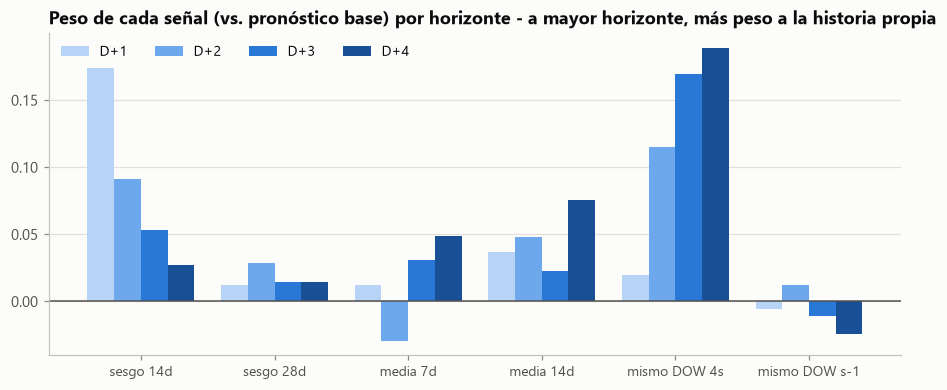

In [21]:
# Explicabilidad del campeón: coeficientes estandarizados por horizonte (entrenado con toda la historia)
final = MLCorrector("ridge", feature_set="log", per_horizon=True).fit(feats.dropna(subset=["real", "roll_mean_14", "ratio_sesgo_14"]))
coefs = final.coefficients()
display(coefs.style.format("{:+.3f}").background_gradient(cmap=COLORS["cmap_div"], vmin=-0.15, vmax=0.15, axis=None))
coefs.to_csv(OUTPUT_DIR / "t3_coeficientes.csv")
key = ["log_sesgo_14", "log_sesgo_28", "log_media7_vs_pron", "log_media14_vs_pron", "log_dow4s_vs_pron", "log_lag_dow_vs_pron"]
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(key)); wb = 0.2
for j, h in enumerate(coefs.columns):
    ax.bar(x + (j - 1.5) * wb, coefs.loc[key, h], width=wb, color=RAMP[j], label=h)
ax.axhline(0, color=COLORS["ink2"], lw=1)
ax.set_xticks(x, ["sesgo 14d", "sesgo 28d", "media 7d", "media 14d", "mismo DOW 4s", "mismo DOW s-1"], fontsize=9)
ax.set_title("Peso de cada señal (vs. pronóstico base) por horizonte - a mayor horizonte, más peso a la historia propia")
ax.legend(ncol=4, fontsize=9)
save(fig, "t3_coeficientes"); plt.show()

In [22]:
r = res_global
hist_w = coefs.loc[["log_media7_vs_pron", "log_media14_vs_pron", "log_dow4s_vs_pron", "log_lag_dow_vs_pron"]].sum()
gain_v1 = (r.loc[V1, "WAPE"] - r.loc[CHAMPION, "WAPE"]) * 100
gain_fb = (r.loc["Corrección sesgo 14d", "WAPE"] - r.loc[CHAMPION, "WAPE"]) * 100
worst_cd_bias = b_cd[CHAMPION].abs().max()
best_other = r.drop(["Base", CHAMPION])["WAPE"].idxmin()
display(Markdown(f'''
**Resultados Tarea 3**
- El pronóstico base obtiene **WAPE {r.loc['Base','WAPE']:.1%}** en las filas de test. El modelo campeón (**{CHAMPION}**) baja a
  **{r.loc[CHAMPION,'WAPE']:.1%}** (−{r.loc[CHAMPION,'mejora_WAPE_vs_base_pp']:.1f} pp, **{r.loc[CHAMPION,'mejora_relativa']:.0%} menos error**) y el bias global pasa de {r.loc['Base','Bias']:+.1%} a {r.loc[CHAMPION,'Bias']:+.1%}
  (|bias| ≤ {worst_cd_bias:.1%} en todos los CD).
- Supera al base en el {wins.loc[CHAMPION,'folds_mejor_que_base']:.0%} de los folds y al fallback en el {wins.loc[CHAMPION,'folds_mejor_que_fallback']:.0%}; es el mejor modelo en
  {int((w_cd[MODEL_NAMES].idxmin(axis=1) == CHAMPION).sum())}/6 CDs y {int((w_h[MODEL_NAMES].idxmin(axis=1) == CHAMPION).sum())}/4 horizontes.
- **Descomposición de la ganancia:** corregir el sesgo de nivel (regla simple, sin ML) explica la mayor parte: {r.loc['Base','WAPE']:.1%} -> {r.loc['Corrección sesgo 14d','WAPE']:.1%}.
  El ML agrega **−{gain_fb:.1f} pp** adicionales, concentrados en **D+3/D+4** ({w_h.loc['D+4','Corrección sesgo 14d']:.1%} -> {w_h.loc['D+4',CHAMPION]:.1%} en D+4), donde el base es más ruidoso y conviene apoyarse en la historia.
  Los coeficientes lo confirman: el peso total de las señales históricas pasa de {hist_w['D+1']:+.2f} en D+1 a {hist_w['D+4']:+.2f} en D+4.
- **Iteración v1 -> v2:** pasar a features log-relativas y a un modelo por horizonte mejoró {gain_v1:.1f} pp sobre la v1 y eliminó el sesgo de −5% en NORTE. El bootstrap por semanas confirma que la mejora sobre el fallback y sobre la v1 no es ruido (ver IC95%).
- **Por qué Ridge y no HGB:** con ~1.000 filas de entrenamiento el árbol no supera al lineal ({best_other} es el siguiente mejor); el Ridge es interpretable, estable y,
  al no usar el ID del CD, **transferible a CDs nuevos** (clave para Cold Start).
- **Hallazgos honestos:** (i) en CD_NORTE el base ya es bueno (WAPE {w_cd.loc['CD_NORTE','Base']:.1%}) y la mejora absoluta es menor; (ii) con poca historia el ML es *peor* que la regla simple (ver Tarea 4);
  (iii) con 60 días no se pueden capturar efectos mensuales ni feriados; (iv) el último fold tiene menos filas (solo horizontes cortos), por eso su WAPE es menor.
'''))


**Resultados Tarea 3**
- El pronóstico base obtiene **WAPE 20.7%** en las filas de test. El modelo campeón (**ML ridge log por horizonte**) baja a
  **6.6%** (−14.1 pp, **68% menos error**) y el bias global pasa de +6.6% a +0.3%
  (|bias| ≤ 2.5% en todos los CD).
- Supera al base en el 100% de los folds y al fallback en el 100%; es el mejor modelo en
  4/6 CDs y 3/4 horizontes.
- **Descomposición de la ganancia:** corregir el sesgo de nivel (regla simple, sin ML) explica la mayor parte: 20.7% -> 9.4%.
  El ML agrega **−2.9 pp** adicionales, concentrados en **D+3/D+4** (14.9% -> 8.9% en D+4), donde el base es más ruidoso y conviene apoyarse en la historia.
  Los coeficientes lo confirman: el peso total de las señales históricas pasa de +0.06 en D+1 a +0.29 en D+4.
- **Iteración v1 -> v2:** pasar a features log-relativas y a un modelo por horizonte mejoró 1.7 pp sobre la v1 y eliminó el sesgo de −5% en NORTE. El bootstrap por semanas confirma que la mejora sobre el fallback y sobre la v1 no es ruido (ver IC95%).
- **Por qué Ridge y no HGB:** con ~1.000 filas de entrenamiento el árbol no supera al lineal (ML ridge log global es el siguiente mejor); el Ridge es interpretable, estable y,
  al no usar el ID del CD, **transferible a CDs nuevos** (clave para Cold Start).
- **Hallazgos honestos:** (i) en CD_NORTE el base ya es bueno (WAPE 9.6%) y la mejora absoluta es menor; (ii) con poca historia el ML es *peor* que la regla simple (ver Tarea 4);
  (iii) con 60 días no se pueden capturar efectos mensuales ni feriados; (iv) el último fold tiene menos filas (solo horizontes cortos), por eso su WAPE es menor.


## 4. Tarea 4 - Regla de resiliencia: Gate de historia mínima (Cold Start)

`HistoryGate` mide la **historia continua** por CD (días consecutivos con dato válido terminando en la fecha de referencia - 1; un hueco o un valor inválido corta la racha) y decide:
- **≥ 45 días → `MODEL`**: el CD entra al entrenamiento y se le sirve el modelo complementario.
- **< 45 días → `FALLBACK`**: cadena segura **(1) corrección por sesgo móvil 14d** si hay ≥ 7 días de errores observados, **(2) pronóstico base** si no.
- `ResilientForecaster` captura cualquier excepción (datos corruptos, fallo de entrenamiento o de inferencia) y degrada a fallback con un log: **nunca lanza excepción** al servicio.

Como los 6 CD tienen 60 días completos, se construyen escenarios de estrés al 15-feb (día 46):

In [23]:
REF = pd.Timestamp("2026-02-15")
a_s = actuals.copy()
f_s = fva.drop(columns=["error", "semana", "dow"]).copy()
# Escenario A: CD_ESTE abrió el 20-ene (26 días de historia)
a_s = a_s[~((a_s["centro_distribucion"] == "CD_ESTE") & (a_s["fecha"] < "2026-01-20"))]
f_s = f_s[~((f_s["centro_distribucion"] == "CD_ESTE") & (f_s["fecha_despacho"] < "2026-01-20"))]
# Escenario B: CD_SUR tiene un hueco de datos el 1-feb (la racha continua se corta)
a_s = a_s[~((a_s["centro_distribucion"] == "CD_SUR") & (a_s["fecha"] == "2026-02-01"))]
# Escenario C: CD_OESTE con un valor corrupto (negativo) el 10-feb
a_s.loc[(a_s["centro_distribucion"] == "CD_OESTE") & (a_s["fecha"] == "2026-02-10"), "real"] = -1
# Escenario D: CD_NUEVO sin ninguna historia (solo existe el pronóstico base)
nuevo = f_s[(f_s["centro_distribucion"] == "CD_NORTE") & (f_s["fecha_emision"] >= REF)].assign(centro_distribucion="CD_NUEVO", real=np.nan)
f_s = pd.concat([f_s, nuevo], ignore_index=True)

gate = HistoryGate(min_days=MIN_HISTORY_DAYS)
decisions = gate.evaluate(a_s, sorted(f_s["centro_distribucion"].unique()), REF)
gate_df = HistoryGate.to_frame(decisions)
gate_df["escenario"] = gate_df["centro_distribucion"].map({"CD_ESTE": "A: abrió hace 26 días", "CD_SUR": "B: hueco de datos 1-feb",
                                                         "CD_OESTE": "C: valor corrupto 10-feb", "CD_NUEVO": "D: CD sin historia"}).fillna("normal")
display(gate_df)

a_clean = a_s[a_s["real"] >= 0]  # el valor corrupto se excluye antes de construir features
feats_s = build_features(f_s, a_clean)
rf = ResilientForecaster(gate=gate).fit(feats_s, a_s, REF)
serv = rf.predict(feats_s[feats_s["fecha_emision"] >= REF])
display(serv.groupby(["centro_distribucion", "fuente"]).size().unstack(fill_value=0))
gate_df.to_csv(OUTPUT_DIR / "t4_gate_escenarios.csv", index=False)

,centro_distribucion,dias_historia_continua,modo,motivo,escenario
0,CD_CENTRO,45,MODEL,45 días >= 45,normal
1,CD_ESTE,26,FALLBACK,26 días < 45,A: abrió hace 26 días
2,CD_NORTE,45,MODEL,45 días >= 45,normal
3,CD_NUEVO,0,FALLBACK,0 días < 45,D: CD sin historia
4,CD_OESTE,4,FALLBACK,4 días < 45,C: valor corrupto 10-feb
5,CD_PACIFICO,45,MODEL,45 días >= 45,normal
6,CD_SUR,13,FALLBACK,13 días < 45,B: hueco de datos 1-feb


fuente,FALLBACK_BASE,FALLBACK_SESGO,MODEL
centro_distribucion,,,
CD_CENTRO,0,0,50
CD_ESTE,0,50,0
CD_NORTE,0,0,50
CD_NUEVO,50,0,0
CD_OESTE,0,50,0
CD_PACIFICO,0,0,50
CD_SUR,0,50,0


In [24]:
# Robustez: entradas degeneradas no deben lanzar excepción
casos = {
    "Reales vacíos": (feats, actuals.iloc[0:0]),
    "Reales todos NaN": (feats, actuals.assign(real=np.nan)),
    "Features sin columnas de sesgo": (feats.drop(columns=["ratio_sesgo_14"]).assign(ratio_sesgo_14=np.nan), actuals),
}
logging.getLogger("logistica.gate").setLevel(logging.ERROR)  # los warnings esperados ya se ven en el resumen
for nombre, (f_bad, a_bad) in casos.items():
    out = ResilientForecaster().fit(f_bad, a_bad, REF).predict(f_bad[f_bad["fecha_emision"] >= REF])
    print(f"{nombre:32s} -> sin excepción - fuentes: {out['fuente'].value_counts().to_dict()} - nulos en predicción: {out['pronostico_corregido'].isna().sum()}")
logging.getLogger("logistica.gate").setLevel(logging.WARNING)

Reales vacíos                    -> sin excepción - fuentes: {'FALLBACK_SESGO': 300} - nulos en predicción: 0
Reales todos NaN                 -> sin excepción - fuentes: {'FALLBACK_SESGO': 300} - nulos en predicción: 0
Features sin columnas de sesgo   -> sin excepción - fuentes: {'FALLBACK_BASE': 300} - nulos en predicción: 0


### 4.1 Argumento cuantitativo para el umbral
Se simula que **todos** los CD tienen solo L días de historia antes de una fecha de corte (se truncan datos y se recalculan features,
así que las ventanas rolling también quedan incompletas), se entrena y se evalúa sobre los pronósticos emitidos en la semana siguiente.
Se repite en **3 fechas de corte** (8, 15 y 22 de febrero) para medir estabilidad.

,Base,Corrección sesgo 14d,ML ridge raw global,ML ridge log por horizonte,n_cortes,ganancia_vs_fallback_pp,sd_champion_pp
dias_historia,,,,,,,
7,20.8%,11.3%,15.7%,21.9%,3,-10.6,1.2
10,20.8%,9.2%,14.5%,12.1%,3,-3.0,1.1
14,20.8%,9.1%,11.2%,11.2%,3,-2.2,2.9
21,20.8%,9.0%,9.4%,8.7%,3,+0.3,1.0
28,20.8%,9.0%,8.0%,7.0%,3,+2.0,0.6
35,20.8%,9.0%,7.9%,6.6%,3,+2.5,0.5
42,20.5%,8.9%,7.6%,6.2%,2,+2.7,0.8
45,20.5%,8.9%,7.6%,6.1%,2,+2.8,0.8


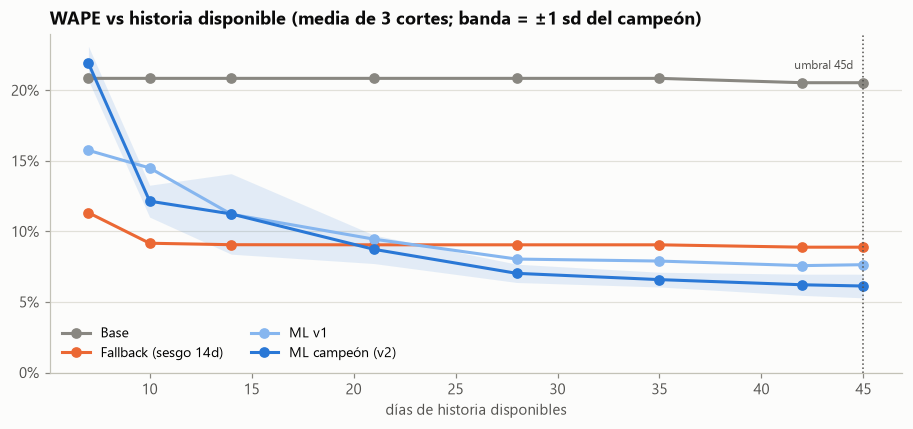

In [25]:
lengths = [7, 10, 14, 21, 28, 35, 42, 45]
sens_factories = [BaselineModel, lambda: RollingBiasCorrector(14),
                  lambda: MLCorrector("ridge", feature_set="raw", per_horizon=False),
                  lambda: MLCorrector("ridge", feature_set="log", per_horizon=True)]
fva_clean = fva.drop(columns=["error", "semana", "dow"])
sens_runs = []
for ts in pd.to_datetime(["2026-02-08", "2026-02-15", "2026-02-22"]):
    avail = (ts - actuals["fecha"].min()).days
    s_ = history_sensitivity(fva_clean, actuals, sens_factories, [L for L in lengths if L <= avail], ts, test_days=7)
    sens_runs.append(s_.assign(corte=ts.date()))
sens_all = pd.concat(sens_runs).reset_index()
M_ = ["Base", "Corrección sesgo 14d", V1, CHAMPION]
sens = sens_all.groupby("dias_historia")[M_].mean()
sens_sd = sens_all.groupby("dias_historia")[M_].std()
sens["n_cortes"] = sens_all.groupby("dias_historia").size()
sens["ganancia_vs_fallback_pp"] = (sens["Corrección sesgo 14d"] - sens[CHAMPION]) * 100
sens["sd_champion_pp"] = sens_sd[CHAMPION] * 100
display(sens.style.format({**{m: "{:.1%}" for m in M_}, "ganancia_vs_fallback_pp": "{:+.1f}", "sd_champion_pp": "{:.1f}"}))
sens_all.to_csv(OUTPUT_DIR / "t4_sensibilidad_umbral_detalle.csv", index=False); sens.to_csv(OUTPUT_DIR / "t4_sensibilidad_umbral.csv")

fig, ax = plt.subplots(figsize=(10, 4))
for n, c, lab in [("Base", COLORS["base"], "Base"), ("Corrección sesgo 14d", COLORS["fallback"], "Fallback (sesgo 14d)"), (V1, COLORS["light"], "ML v1"), (CHAMPION, COLORS["modelo"], "ML campeón (v2)")]:
    ax.plot(sens.index, sens[n], marker="o", color=c, label=lab)
    if n == CHAMPION:
        ax.fill_between(sens.index, sens[n] - sens_sd[n], sens[n] + sens_sd[n], color=c, alpha=0.12, lw=0)
ax.axvline(MIN_HISTORY_DAYS, color=COLORS["ink2"], lw=1, ls=":"); ax.text(MIN_HISTORY_DAYS - 0.5, 0.215, "umbral 45d", ha="right", fontsize=8, color=COLORS["ink2"])
ax.yaxis.set_major_formatter(pct); ax.set_xlabel("días de historia disponibles"); ax.set_ylim(0, 0.24)
ax.set_title("WAPE vs historia disponible (media de 3 cortes; banda = ±1 sd del campeón)"); ax.legend(ncol=2, fontsize=9)
save(fig, "t4_sensibilidad_umbral"); plt.show()

In [26]:
s = sens
cross = int(s.index[(s[CHAMPION] < s["Corrección sesgo 14d"])].min())
vol_cd_dia = actuals["real"].mean()
gap28_45 = (s.loc[28, CHAMPION] - s.loc[45, CHAMPION])
gain45 = (s.loc[45, "Corrección sesgo 14d"] - s.loc[45, CHAMPION])
gain28 = (s.loc[28, "Corrección sesgo 14d"] - s.loc[28, CHAMPION])
display(Markdown(f'''
**Argumento cuantitativo**
- **Bajo ~{cross} días el modelo es peor que el fallback.** Con 7 días el campeón tiene WAPE {s.loc[7,CHAMPION]:.1%}, *igual o peor que el base* ({s.loc[7,'Base']:.1%}), y con 14 días {s.loc[14,CHAMPION]:.1%} vs {s.loc[14,'Corrección sesgo 14d']:.1%} del fallback.
  Las ventanas rolling incompletas y las pocas filas de entrenamiento lo hacen sobreajustar. **Un umbral bajo es el riesgo principal**: activar el modelo demasiado pronto empeora el pronóstico.
- **El modelo supera al fallback desde ~{cross} días** y sigue mejorando: {s.loc[21,CHAMPION]:.1%} (21d) -> {s.loc[28,CHAMPION]:.1%} (28d) -> {s.loc[35,CHAMPION]:.1%} (35d) -> {s.loc[45,CHAMPION]:.1%} (45d).
  La dispersión entre cortes también baja (sd {sens_sd.loc[14,CHAMPION]*100:.1f} pp con 14d vs {sens_sd.loc[45,CHAMPION]*100:.1f} pp con 45d).
- **El fallback es seguro:** se estabiliza en ~{s.loc[14,'Corrección sesgo 14d']:.1%} desde 10–14 días y siempre está muy por debajo del base. Esperar en fallback cuesta poco.

**Ventajas y riesgos de mover el umbral**
| Umbral | Ventaja | Riesgo |
|---|---|---|
| **< 21 días** | Activa el modelo casi de inmediato | WAPE peor que el fallback (hasta {(s.loc[7,CHAMPION]-s.loc[7,'Corrección sesgo 14d'])*100:+.0f} pp con 7d) -> **no recomendable** |
| **28 días** | El CD accede al modelo 17 días antes; ya gana {gain28*100:.1f} pp al fallback (≈ {gain28*vol_cd_dia:,.0f} u/día de error evitado por CD) | Queda {gap28_45*100:.1f} pp peor que con 45d; las ventanas de 28d recién completan 4 semanas de patrón semanal |
| **45 días (actual)** | Mejor WAPE ({s.loc[45,CHAMPION]:.1%}) y menor varianza; > 6 semanas de cada día de semana; ventanas de 28d completas con margen para validar | 17 días más en fallback que con 28d: costo ≈ {gain28*100:.1f} pp × {vol_cd_dia:,.0f} u/día ≈ {gain28*vol_cd_dia*17:,.0f} u de error acumulado por CD nuevo |
| **> 60 días** | Podría capturar estacionalidad mensual | No hay evidencia en esta data de ganancia adicional; CDs nuevos o con huecos quedan mucho tiempo en fallback |

**Recomendación:** mantener **45 días como default** (es el punto de mejor WAPE y menor varianza medido) y hacerlo **configurable por CD**. Complementarlo con un
**gate de desempeño**: entre 28 y 45 días el modelo corre en *shadow mode* y se activa antes solo si su WAPE de las últimas 2 semanas es ≤ al del fallback.
Monitorear en producción el % de CDs en fallback y el WAPE por modo.
'''))


**Argumento cuantitativo**
- **Bajo ~21 días el modelo es peor que el fallback.** Con 7 días el campeón tiene WAPE 21.9%, *igual o peor que el base* (20.8%), y con 14 días 11.2% vs 9.1% del fallback.
  Las ventanas rolling incompletas y las pocas filas de entrenamiento lo hacen sobreajustar. **Un umbral bajo es el riesgo principal**: activar el modelo demasiado pronto empeora el pronóstico.
- **El modelo supera al fallback desde ~21 días** y sigue mejorando: 8.7% (21d) -> 7.0% (28d) -> 6.6% (35d) -> 6.1% (45d).
  La dispersión entre cortes también baja (sd 2.9 pp con 14d vs 0.8 pp con 45d).
- **El fallback es seguro:** se estabiliza en ~9.1% desde 10–14 días y siempre está muy por debajo del base. Esperar en fallback cuesta poco.

**Ventajas y riesgos de mover el umbral**
| Umbral | Ventaja | Riesgo |
|---|---|---|
| **< 21 días** | Activa el modelo casi de inmediato | WAPE peor que el fallback (hasta +11 pp con 7d) -> **no recomendable** |
| **28 días** | El CD accede al modelo 17 días antes; ya gana 2.0 pp al fallback (≈ 29 u/día de error evitado por CD) | Queda 0.9 pp peor que con 45d; las ventanas de 28d recién completan 4 semanas de patrón semanal |
| **45 días (actual)** | Mejor WAPE (6.1%) y menor varianza; > 6 semanas de cada día de semana; ventanas de 28d completas con margen para validar | 17 días más en fallback que con 28d: costo ≈ 2.0 pp × 1,460 u/día ≈ 501 u de error acumulado por CD nuevo |
| **> 60 días** | Podría capturar estacionalidad mensual | No hay evidencia en esta data de ganancia adicional; CDs nuevos o con huecos quedan mucho tiempo en fallback |

**Recomendación:** mantener **45 días como default** (es el punto de mejor WAPE y menor varianza medido) y hacerlo **configurable por CD**. Complementarlo con un
**gate de desempeño**: entre 28 y 45 días el modelo corre en *shadow mode* y se activa antes solo si su WAPE de las últimas 2 semanas es ≤ al del fallback.
Monitorear en producción el % de CDs en fallback y el WAPE por modo.


## 5. Tarea 5 - Arquitectura e infraestructura en AWS

Diagrama editable en `docs/arquitectura_aws.drawio` (draw.io, íconos oficiales AWS); abajo, la versión Mermaid y el render.

```mermaid
flowchart LR
    subgraph Fuentes
        ERP[(ERP / OMS<br/>pedidos, capacidad)]
        FB[Pronóstico base<br/>sistema actual]
        APP[App B2B / Web<br/>clientes y agentes]
    end

    subgraph Ingesta_y_Datos["Persistencia · Data Lake"]
        S3R[(S3 raw)]
        GLUE[Glue Jobs + Data Catalog<br/>validación de calidad]
        S3C[(S3 curated<br/>Parquet particionado)]
        ATH[Athena<br/>consultas ad-hoc]
    end

    subgraph Batch["Procesamiento batch / re-entrenamiento"]
        EB[EventBridge Scheduler<br/>diario / semanal]
        SF[Step Functions<br/>orquestación]
        GATE[Lambda: Gate 45d<br/>por CD]
        SMP[SageMaker Pipelines<br/>features → train → backtest]
        REG[SageMaker Model Registry<br/>aprobación por WAPE]
        BT[SageMaker Batch Transform<br/>pronóstico corregido D+1..D+4]
    end

    subgraph Serving["Servicio de recomendación / inferencia"]
        APIGW[API Gateway<br/>auth Cognito/IAM]
        LREC[Lambda / ECS Fargate<br/>motor de fecha recomendada]
        SME[SageMaker Endpoint<br/>serverless]
        DDB[(DynamoDB<br/>pronóstico corregido,<br/>capacidad, estado gate)]
    end

    subgraph Obs["Monitoreo y estados"]
        CW[CloudWatch<br/>logs, alarmas, % fallback]
        MM[SageMaker Model Monitor<br/>drift]
        RDS[(Aurora / RDS<br/>métricas WAPE/Bias,<br/>historial de decisiones)]
        QS[QuickSight<br/>dashboard KPIs]
    end

    ERP --> S3R
    FB --> S3R
    S3R --> GLUE --> S3C --> ATH
    EB --> SF --> GATE --> SMP --> REG --> BT
    S3C --> SMP
    BT --> DDB
    GATE -->|estado por CD| DDB
    APP --> APIGW --> LREC
    LREC --> DDB
    LREC -.on-demand.-> SME
    LREC -->|eventos de pedido| S3R
    SMP --> RDS
    LREC --> CW
    SME --> MM
    RDS --> QS
    CW -->|alarma| SF
```

| Componente | Rol | Interacciones / razonamiento |
|---|---|---|
| **S3 raw / curated + Glue + Athena** | *Persistencia*: data lake con histórico de pedidos, pronósticos, capacidad y plan | Glue valida esquema y calidad (nulos, huecos, negativos) antes de que lleguen al modelo; Parquet particionado por fecha/CD |
| **EventBridge + Step Functions** | *Batch*: orquesta el pipeline diario (inferencia) y semanal (re-entrenamiento) | Reintentos y ramas de error explícitas; si algo falla, se mantiene el último pronóstico válido |
| **Lambda Gate 45d** | Evalúa historia continua por CD y publica el modo (MODEL/FALLBACK) | Su salida decide qué CDs entran al entrenamiento y qué fuente se sirve; queda trazada en DynamoDB y RDS |
| **SageMaker Pipelines + Model Registry** | Feature engineering, entrenamiento, backtest rolling-origin y registro | Solo se promueve un modelo si su WAPE de backtest ≤ el campeón y ≤ fallback (*quality gate* automático) |
| **SageMaker Batch Transform** | Genera el pronóstico corregido D+1..D+4 de todos los CDs cada día | Batch porque el pronóstico es diario y por CD: más barato y simple que inferencia online |
| **DynamoDB** | Estado *caliente*: pronóstico corregido, capacidad por slot y estado del gate | Lectura de ms para el servicio de recomendación |
| **API Gateway + Lambda/Fargate** | *Servicio de recomendación*: al crear un pedido, devuelve las fechas sugeridas con utilización proyectada e incentivo | Lee DynamoDB (no llama al modelo en la ruta crítica -> baja latencia y sin dependencia del endpoint). El endpoint serverless queda para re-cálculos on-demand |
| **Aurora/RDS + CloudWatch + Model Monitor + QuickSight** | *Persistencia de métricas y estados*: WAPE/Bias por CD/horizonte, % fallback, decisiones del gate, drift | Alarmas (p.ej., WAPE semanal > umbral o % fallback ↑) disparan re-entrenamiento o rollback |

**Resiliencia end-to-end:** el servicio nunca depende de que el modelo esté disponible: si no hay pronóstico corregido vigente se sirve el fallback (sesgo móvil o base) desde DynamoDB.

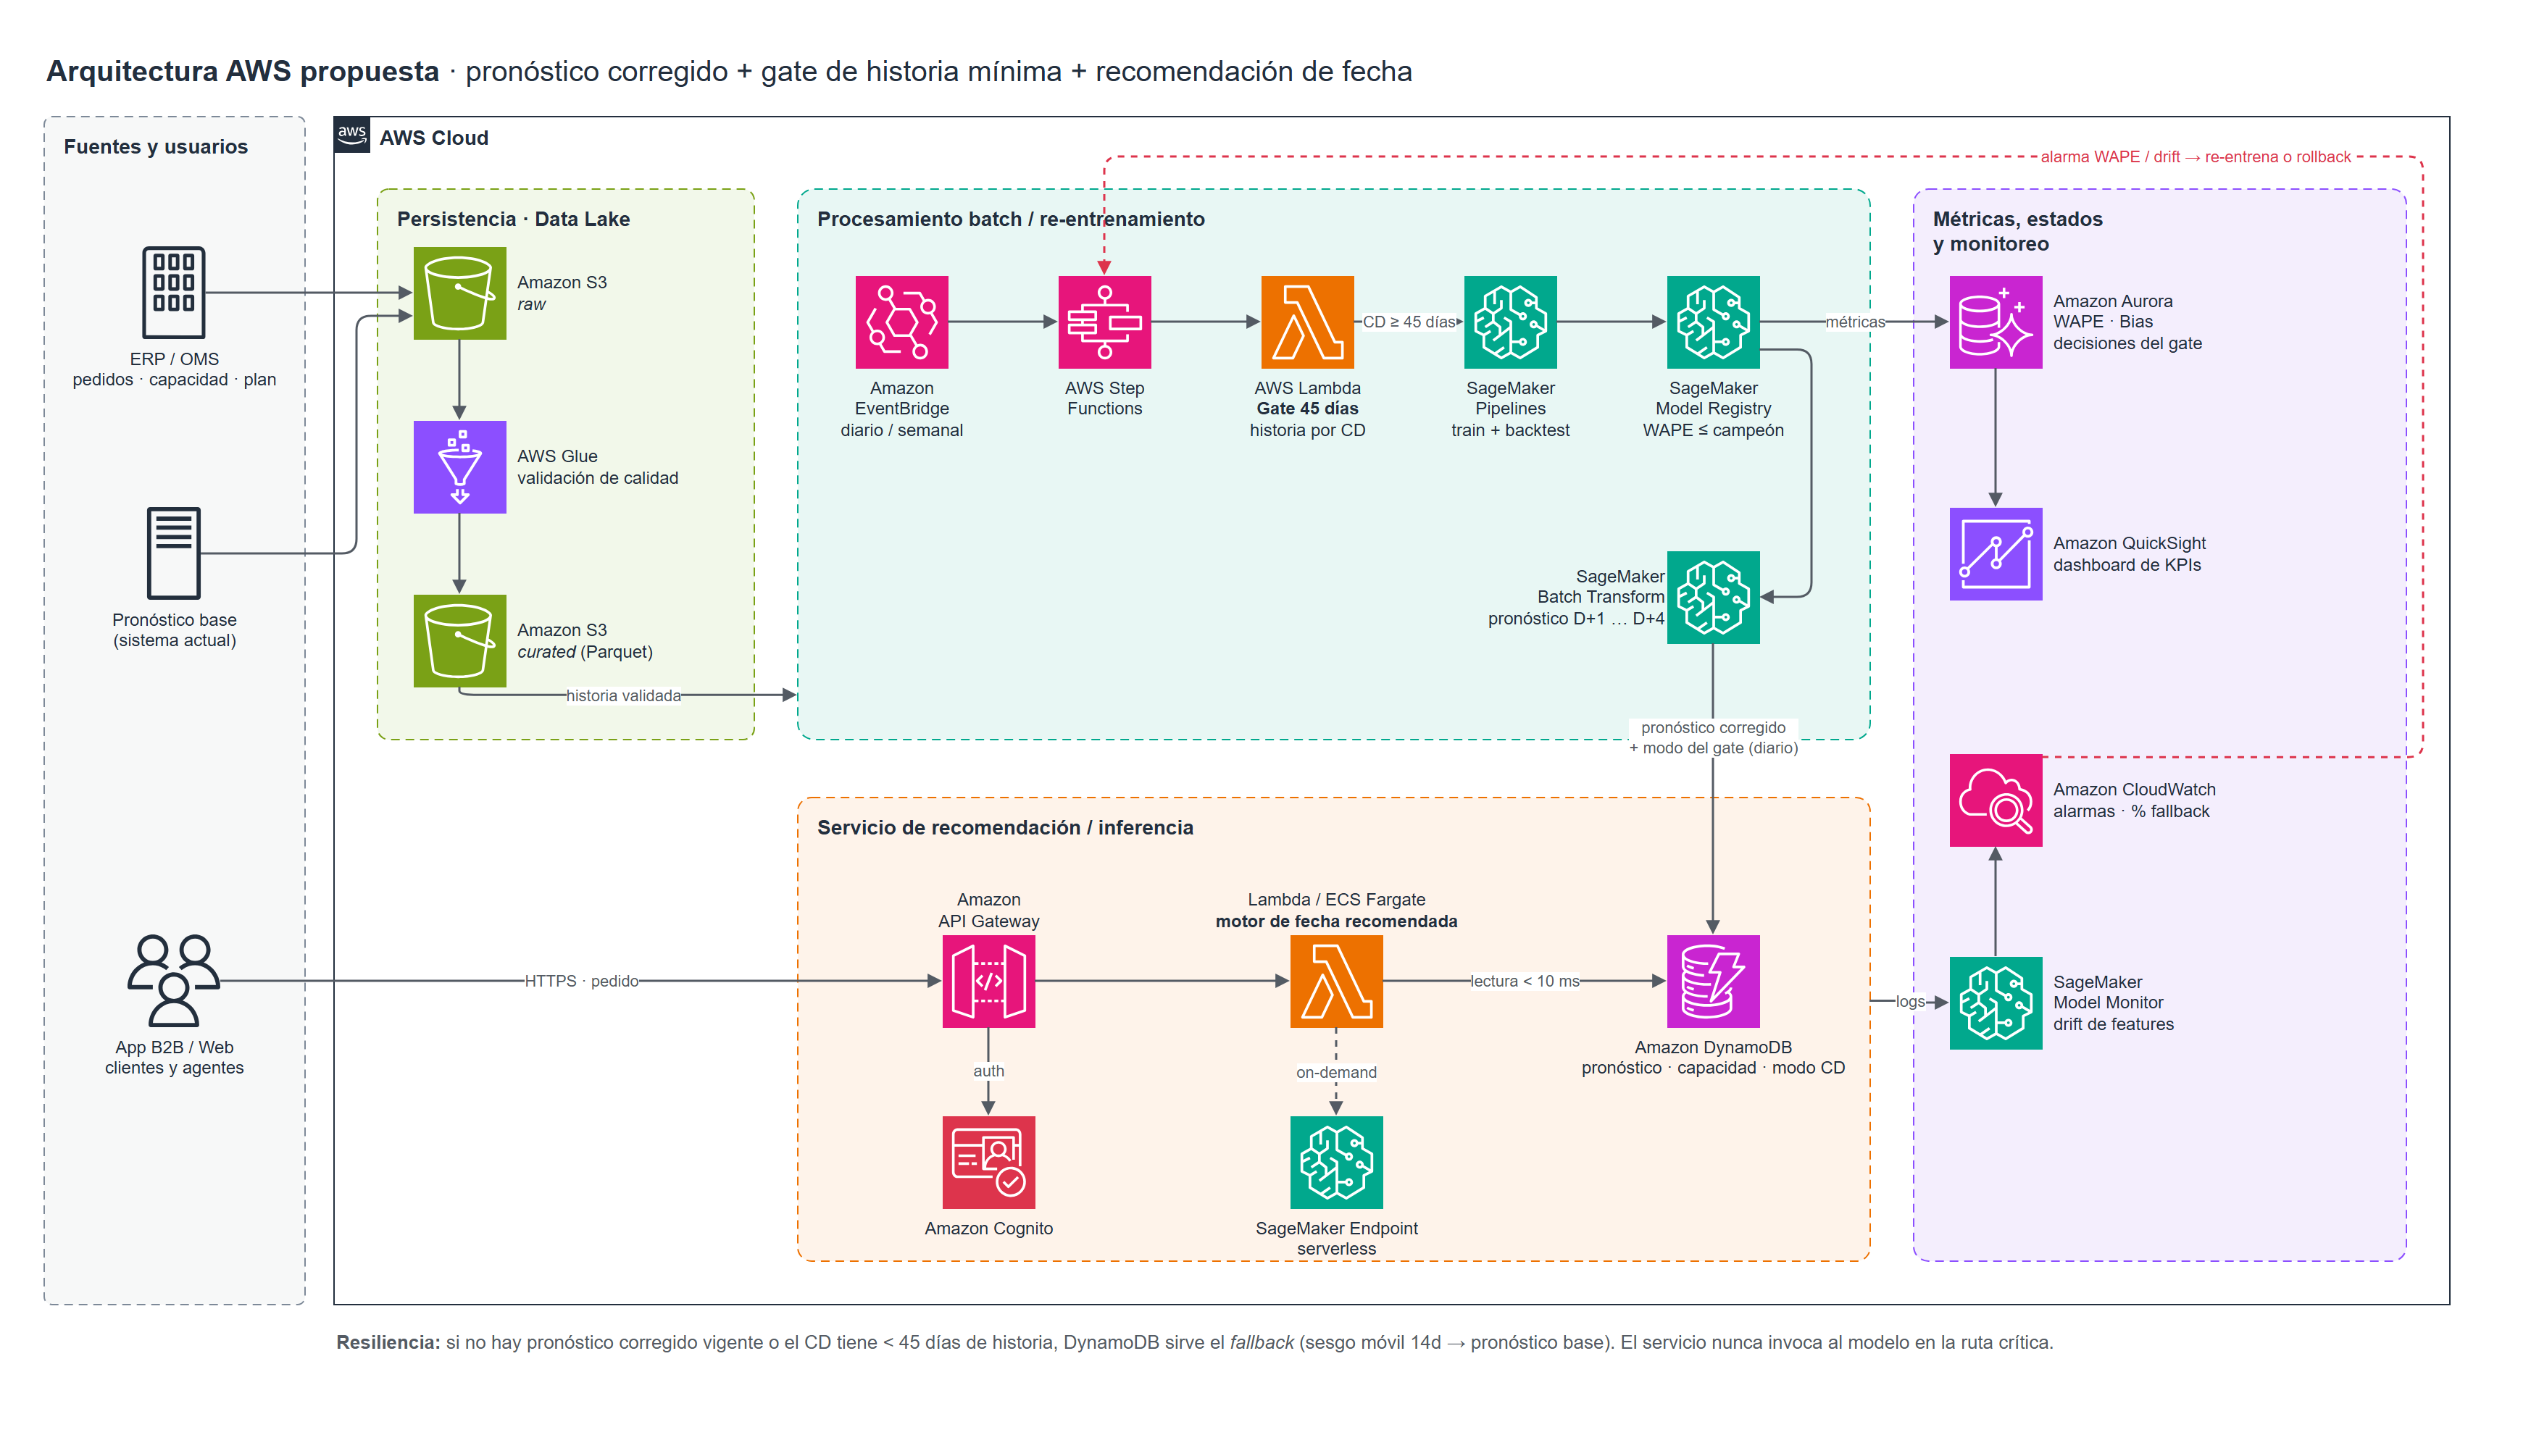

In [27]:
# Diagrama oficial: docs/arquitectura_aws.drawio (draw.io, íconos AWS). Si el PNG no existe, se dibuja una versión simplificada.
from IPython.display import Image
drawio_png = ROOT / "docs" / "arquitectura_aws.png"
if drawio_png.exists():
    display(Image(filename=str(drawio_png), width=1100))
else:
    from logistica.architecture import draw_architecture
    fig = draw_architecture(); save(fig, "t5_arquitectura_aws"); plt.show()

## 6. Impacto en negocio: flota, fletes de emergencia y nivel de servicio

Supuesto operativo (parametrizable): la flota se **reserva con el pronóstico D+2** (acotado a la capacidad del CD).
Si la demanda real supera la reserva -> **flete de emergencia**; si queda por debajo -> **capacidad ociosa** pagada. Camión equivalente = 300 unidades (supuesto ilustrativo).

,dias_cd,dias_con_flete_emergencia,unidades_emergencia,unidades_ociosas,camiones_emergencia_eq,camiones_ociosos_eq,nivel_servicio_sin_emergencia,camiones_emergencia_por_semana,reduccion_emergencia_vs_base,reduccion_ociosa_vs_base
modelo,,,,,,,,,,
Base,222,117,"45,400","14,044",151,47,86.0%,25.2,0%,0%
Corrección sesgo 14d,222,114,"15,086","9,488",50,32,95.4%,8.4,67%,32%
ML ridge raw global,222,94,"11,603","13,104",39,44,96.4%,6.4,74%,7%
ML ridge log por horizonte,222,98,"9,713","10,727",32,36,97.0%,5.4,79%,24%


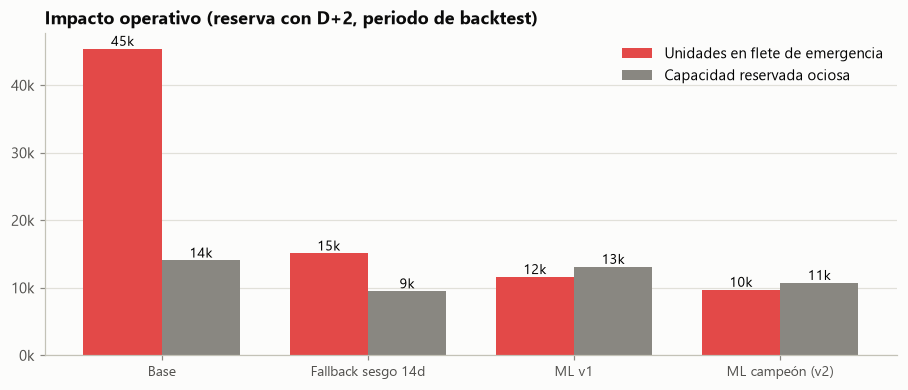

In [28]:
imp = fleet_impact(bt, pkg.capacidad, ["Base", "Corrección sesgo 14d", V1, CHAMPION], horizonte="D+2", unidades_por_camion=300)
semanas_bt = bt["fecha_despacho"].dt.to_period("W").nunique()
imp["camiones_emergencia_por_semana"] = imp["camiones_emergencia_eq"] / semanas_bt
imp["reduccion_emergencia_vs_base"] = 1 - imp["unidades_emergencia"] / imp.loc["Base", "unidades_emergencia"]
imp["reduccion_ociosa_vs_base"] = 1 - imp["unidades_ociosas"] / imp.loc["Base", "unidades_ociosas"]
display(imp.style.format({"unidades_emergencia": "{:,.0f}", "unidades_ociosas": "{:,.0f}", "camiones_emergencia_eq": "{:,.0f}", "camiones_ociosos_eq": "{:,.0f}",
                          "nivel_servicio_sin_emergencia": "{:.1%}", "camiones_emergencia_por_semana": "{:.1f}",
                          "reduccion_emergencia_vs_base": "{:.0%}", "reduccion_ociosa_vs_base": "{:.0%}"}))
imp.to_csv(OUTPUT_DIR / "impacto_flota.csv")

imp_cd = []
for cd, g in bt.groupby("centro_distribucion"):
    t = fleet_impact(g, pkg.capacidad, ["Base", "Corrección sesgo 14d", CHAMPION], "D+2")
    imp_cd.append(t[["unidades_emergencia", "unidades_ociosas"]].stack().rename(cd))
imp_cd = pd.concat(imp_cd, axis=1).T
display(imp_cd.style.format("{:,.0f}"))

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(imp)); wb = 0.38
ax.bar(x - wb/2, imp["unidades_emergencia"], width=wb, color=COLORS["sub"], label="Unidades en flete de emergencia")
ax.bar(x + wb/2, imp["unidades_ociosas"], width=wb, color=COLORS["base"], label="Capacidad reservada ociosa")
for xi, (e, o) in enumerate(zip(imp["unidades_emergencia"], imp["unidades_ociosas"])):
    ax.text(xi - wb/2, e, f"{e/1000:.0f}k", ha="center", va="bottom", fontsize=9); ax.text(xi + wb/2, o, f"{o/1000:.0f}k", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, ["Base", "Fallback sesgo 14d", "ML v1", "ML campeón (v2)"], fontsize=9); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.set_title("Impacto operativo (reserva con D+2, periodo de backtest)"); ax.legend()
save(fig, "impacto_flota"); plt.show()

In [29]:
i0, i1 = imp.loc["Base"], imp.loc[CHAMPION]
idle = imp_cd.xs("unidades_ociosas", axis=1, level=1)
idle_txt = ", ".join(f"{cd.replace('CD_','')} {idle.loc[cd,'Base']:,.0f}->{idle.loc[cd,CHAMPION]:,.0f}" for cd in idle.index)
display(Markdown(f'''
**Impacto estimado (periodo de backtest, {semanas_bt} semanas, 6 CD):**
- **Fletes de emergencia:** {i0.unidades_emergencia:,.0f} -> {i1.unidades_emergencia:,.0f} unidades (**−{i1.reduccion_emergencia_vs_base:.0%}**; la v1 lograba −{imp.loc[V1,'reduccion_emergencia_vs_base']:.0%}), ≈ {i0.camiones_emergencia_por_semana:.0f} -> {i1.camiones_emergencia_por_semana:.0f} camiones-eq por semana.
  Días-CD con necesidad de emergencia: {i0.dias_con_flete_emergencia:.0f} -> {i1.dias_con_flete_emergencia:.0f}.
- **Capacidad ociosa:** {i0.unidades_ociosas:,.0f} -> {i1.unidades_ociosas:,.0f} unidades (**{-i1.reduccion_ociosa_vs_base:+.0%}**). Por CD: {idle_txt}.
  El aumento en NORTE, ESTE y SUR es esperable: el base los subestimaba tanto que *nunca* sobraba flota; un pronóstico centrado se equivoca en ambos sentidos.
  Como el flete de emergencia cuesta bastante más que la capacidad ociosa, el siguiente paso es reservar con un **cuantil** (p.ej. P60) en lugar de la media.
- **Nivel de servicio** sin depender de emergencia: {i0.nivel_servicio_sin_emergencia:.1%} -> {i1.nivel_servicio_sin_emergencia:.1%}.
- Se suma la palanca de aplanamiento (Tarea 2): el slotting dinámico elimina los {k0.dias_cd_sobre_capacidad:.0f} días-CD sobre capacidad ({k0.unidades_sobre_capacidad:,.0f} u) moviendo {kd.pct_volumen_movido:.1%} del volumen; esas unidades hoy son fletes de emergencia inevitables aunque el pronóstico sea perfecto.

**KPIs propuestos**
| Tipo | KPI | Meta indicativa |
|---|---|---|
| Pronóstico | WAPE y Bias por CD × horizonte (semanal) | WAPE < 8%, Bias en ±3% |
| Flota | % unidades en flete de emergencia; costo flete emergencia / unidad | −50% vs base |
| Flota | Utilización de flota reservada; capacidad ociosa | > 90% utilización |
| Curva | Ratio pico/promedio semanal; % días-CD > 100% capacidad | pico/promedio < 1.15 |
| Servicio | OTIF; adhesión al plan; aceptación de fecha recomendada | OTIF > 95% |
| Operación del modelo | % CDs en fallback; latencia API p95; drift de features | alarmas en CloudWatch |
'''))


**Impacto estimado (periodo de backtest, 6 semanas, 6 CD):**
- **Fletes de emergencia:** 45,400 -> 9,713 unidades (**−79%**; la v1 lograba −74%), ≈ 25 -> 5 camiones-eq por semana.
  Días-CD con necesidad de emergencia: 117 -> 98.
- **Capacidad ociosa:** 14,044 -> 10,727 unidades (**-24%**). Por CD: CENTRO 6,529->2,183, ESTE 0->1,045, NORTE 366->3,597, OESTE 3,357->661, PACIFICO 3,792->679, SUR 0->2,562.
  El aumento en NORTE, ESTE y SUR es esperable: el base los subestimaba tanto que *nunca* sobraba flota; un pronóstico centrado se equivoca en ambos sentidos.
  Como el flete de emergencia cuesta bastante más que la capacidad ociosa, el siguiente paso es reservar con un **cuantil** (p.ej. P60) en lugar de la media.
- **Nivel de servicio** sin depender de emergencia: 86.0% -> 97.0%.
- Se suma la palanca de aplanamiento (Tarea 2): el slotting dinámico elimina los 13 días-CD sobre capacidad (1,540 u) moviendo 1.6% del volumen; esas unidades hoy son fletes de emergencia inevitables aunque el pronóstico sea perfecto.

**KPIs propuestos**
| Tipo | KPI | Meta indicativa |
|---|---|---|
| Pronóstico | WAPE y Bias por CD × horizonte (semanal) | WAPE < 8%, Bias en ±3% |
| Flota | % unidades en flete de emergencia; costo flete emergencia / unidad | −50% vs base |
| Flota | Utilización de flota reservada; capacidad ociosa | > 90% utilización |
| Curva | Ratio pico/promedio semanal; % días-CD > 100% capacidad | pico/promedio < 1.15 |
| Servicio | OTIF; adhesión al plan; aceptación de fecha recomendada | OTIF > 95% |
| Operación del modelo | % CDs en fallback; latencia API p95; drift de features | alarmas en CloudWatch |


## 7. Limitaciones, supuestos y fuera de alcance
- **60 días de historia:** no permite modelar estacionalidad mensual, feriados ni eventos; el backtest tiene 6 folds (resultados robustos en signo, no en el decimal).
- **Disponibilidad de información:** se asumió que la demanda real de E-1 está disponible al emitir en E. Si el cierre llega con más rezago, las features rolling se desplazan un día más (cambio de un parámetro).
- **Impacto económico:** el costo de flete de emergencia y la capacidad por camión son supuestos ilustrativos; con tarifas reales el cálculo es directo.
- **Simulación de aplanamiento:** asume que el volumen se desplaza sin pérdida de venta y dentro de la misma semana; la elasticidad real al incentivo debe medirse con el A/B test propuesto.
- **Pronóstico por canal:** el base es por CD; un siguiente paso es corregir por canal (PORTAL_WEB ~50% del volumen) y propagar el bias del plan de clientes como feature.
- **Fuera de alcance:** código de infraestructura (no requerido), tuning exhaustivo de hiperparámetros (ganancia marginal frente al riesgo de sobreajuste con esta muestra), intervalos de predicción (recomendado para dimensionar holgura de flota: cuantiles con el mismo esquema).

In [30]:
print("Archivos generados en outputs/:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" ·", p.name)

Archivos generados en outputs/:
 · impacto_flota.csv
 · impacto_flota.png
 · t1_bias_semanal.png
 · t1_bias_wape.png
 · t1_cd_horizonte.csv
 · t1_consistencia_sesgo.csv
 · t1_por_cd.csv
 · t1_por_horizonte.csv
 · t1_total.csv
 · t2_adhesion_concentracion.png
 · t2_aplanamiento.png
 · t2_bias_plan.csv
 · t2_bias_plan.png
 · t2_capacidad_por_cd.csv
 · t2_fuera_de_plan.csv
 · t2_fuera_de_plan.png
 · t2_metricas_cliente.csv
 · t2_simulacion_aplanamiento.csv
 · t3_backtest_global.csv
 · t3_bias_cd.csv
 · t3_bootstrap.csv
 · t3_coeficientes.csv
 · t3_coeficientes.png
 · t3_resultados.png
 · t3_wape_cd.csv
 · t3_wape_dow.csv
 · t3_wape_fold.csv
 · t3_wape_fold.png
 · t3_wape_fold_cd.png
 · t3_wape_horizonte.csv
 · t4_gate_escenarios.csv
 · t4_sensibilidad_umbral.csv
 · t4_sensibilidad_umbral.png
 · t4_sensibilidad_umbral_detalle.csv
 · t5_arquitectura_aws.png
